# Objective 2 · Session-level smartphone behaviour

At the start of a smartphone session, was the user opening sessions unusually often, making unusually frequent short visits to apps, or doing both? This notebook reproduces the rule-based analysis in `Research_Project_Objective_2.ipynb`. Each session is compared with the same user's earlier behaviour.

The workflow moves from **event records** to **sessions**, reconstructs continuous stretches of app use called **bouts**, and then measures recent activity at each session start. The final table, `decision_features`, contains one row per user–session pair and the label `engagement_pattern_p75`. The intermediate `sessions` and `bout_audit` tables let you trace a label back to the events that contributed to it.

## 1. Load the Objective 1 event stream

Run the cells in order with a Python 3 Jupyter kernel, pandas, NumPy and openpyxl. The input is the prepared event stream in `Datasets/lsapp_objective1.xlsx`. The setup finds the file when Jupyter starts in the project root or the `Notebooks` directory. If your workbook is elsewhere, set `data_path` to its location.

An **episode** has a recorded start, end and duration for one app. An **interaction** is a point observation. Both carry the user ID, session ID and event order needed to put them back into context.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

session_keys = ["user_id", "session_id"]
order_columns = ["user_id", "session_start", "session_id"]
short_limit_seconds = 15

project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent
data_path = project_root / "Datasets" / "lsapp_objective1.xlsx"

df = pd.read_excel(data_path, engine="openpyxl")
required = session_keys + [
    "app_name", "event_class", "timestamp", "start_time", "end_time",
    "duration_seconds", "session_event_number",
]
missing = set(required).difference(df.columns)
if missing:
    raise ValueError(f"Missing event columns in {data_path.name}: {sorted(missing)}")

for column in ["timestamp", "start_time", "end_time"]:
    df[column] = pd.to_datetime(df[column], errors="raise")

n_users = df["user_id"].nunique()
n_sessions = df[session_keys].drop_duplicates().shape[0]
print(f"{data_path.name} | {len(df):,} events | {n_users:,} users | {n_sessions:,} sessions")
display(df.head())

lsapp_objective1.xlsx | 899,349 events | 291 users | 70,979 sessions


,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds,session_event_number
0,0,1,1.0,Minesweeper Classic (Mines),2018-01-16 06:01:05,episode,2018-01-16 06:01:05,2018-01-16 06:01:05,0.0,1
1,0,1,2.0,Minesweeper Classic (Mines),2018-01-16 06:01:07,episode,2018-01-16 06:01:07,2018-01-16 06:01:07,0.0,2
2,0,1,3.0,Minesweeper Classic (Mines),2018-01-16 06:01:08,episode,2018-01-16 06:01:08,2018-01-16 06:01:08,0.0,3
3,0,1,4.0,Minesweeper Classic (Mines),2018-01-16 06:01:09,episode,2018-01-16 06:01:09,2018-01-16 06:01:09,0.0,4
4,0,1,5.0,Minesweeper Classic (Mines),2018-01-16 06:03:44,episode,2018-01-16 06:03:44,2018-01-16 06:03:44,0.0,5


## 2. Audit what the log measures

First check the event classes and where a duration is available. Then look at zero-duration episodes. When timestamps are recorded to whole seconds, equal start and end times leave a brief visit indistinguishable from an instantaneous record. Keep these episodes in counts and give them zero recorded seconds. The short-use measure requires a positive duration below 15 seconds.

In [2]:
df.info()
is_episode = df["event_class"].eq("episode")
is_interaction = df["event_class"].eq("interaction")
assert (is_episode | is_interaction).all()

duration_coverage = pd.crosstab(
    df["event_class"], df["duration_seconds"].notna(), margins=True,
    colnames=["Duration recorded"],
)
display(duration_coverage)
print("Event timestamps with fractional seconds:", df["timestamp"].dt.microsecond.ne(0).sum())

zero_episodes = df.loc[is_episode & df["duration_seconds"].eq(0)]
print(f"Zero-duration episodes: {len(zero_episodes):,} of {is_episode.sum():,} "
      f"({len(zero_episodes) / is_episode.sum():.2%})")
print("With identical start and end:", zero_episodes["start_time"].eq(zero_episodes["end_time"]).sum())
display(zero_episodes[session_keys + ["app_name", "start_time", "end_time", "duration_seconds"]].head())
display(zero_episodes["app_name"].value_counts().head(10).rename("zero_duration_episodes").to_frame())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 899349 entries, 0 to 899348
Data columns (total 10 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   user_id               899349 non-null  int64         
 1   session_id            899349 non-null  int64         
 2   episode_number        585520 non-null  float64       
 3   app_name              899349 non-null  object        
 4   timestamp             899349 non-null  datetime64[ns]
 5   event_class           899349 non-null  object        
 6   start_time            585520 non-null  datetime64[ns]
 7   end_time              585520 non-null  datetime64[ns]
 8   duration_seconds      585520 non-null  float64       
 9   session_event_number  899349 non-null  int64         
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 68.6+ MB


Duration recorded,False,True,All
event_class,,,
episode,0,585520,585520
interaction,313829,0,313829
All,313829,585520,899349


Event timestamps with fractional seconds: 0
Zero-duration episodes: 55,073 of 585,520 (9.41%)
With identical start and end: 55073


,user_id,session_id,app_name,start_time,end_time,duration_seconds
0,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,2018-01-16 06:01:05,0.0
1,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:07,2018-01-16 06:01:07,0.0
2,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:08,2018-01-16 06:01:08,0.0
3,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:09,2018-01-16 06:01:09,0.0
4,0,1,Minesweeper Classic (Mines),2018-01-16 06:03:44,2018-01-16 06:03:44,0.0


,zero_duration_episodes
app_name,
Google Chrome,11776
Facebook Messenger,5075
Minesweeper Classic (Mines),2873
Slidejoy,2752
Instagram,2255
Samsung Pay,2250
DigiHUD Pro Speedometer,2017
Facebook,1844
Google,1752


## 3. Build one row per session

Group records by both `user_id` and `session_id`. Use all event types so interaction-only sessions stay in the analysis. Three time measures answer different questions.

| Measure | What it captures |
|---|---|
| `event_span_seconds` | Time between the earliest and latest event timestamps. A single event has a span of zero. |
| `recorded_episode_seconds` | Sum of recorded episode durations. A session containing only interactions has a missing value. |
| `session_span_seconds` | Time from the earliest observed start to the latest observed end, using the event timestamp for point observations. |

Count short **episodes** here to establish a reference. Later we will compare this count with the number of short **bouts** after joining contiguous fragments.

In [3]:
events = df.assign(
    is_episode=is_episode,
    is_interaction=is_interaction,
    is_zero_episode=is_episode & df["duration_seconds"].eq(0),
    is_short_episode=is_episode & df["duration_seconds"].between(0, short_limit_seconds, inclusive="neither"),
    observed_start=df["start_time"].fillna(df["timestamp"]),
    observed_end=df["end_time"].fillna(df["timestamp"]),
)
sessions = events.groupby(session_keys, as_index=False).agg(
    first_event_time=("timestamp", "min"),
    last_event_time=("timestamp", "max"),
    event_count=("event_class", "size"),
    episode_count=("is_episode", "sum"),
    interaction_count=("is_interaction", "sum"),
    zero_duration_episode_count=("is_zero_episode", "sum"),
    short_episode_count=("is_short_episode", "sum"),
    session_start=("observed_start", "min"),
    session_end=("observed_end", "max"),
    unique_apps_observed=("app_name", "nunique"),
)
# Sum over episode rows only. The left join preserves missing duration for interaction-only sessions.
episode_seconds = df.loc[is_episode].groupby(session_keys)["duration_seconds"].sum()
sessions = sessions.join(episode_seconds.rename("recorded_episode_seconds"), on=session_keys, validate="one_to_one")
sessions["event_span_seconds"] = (sessions["last_event_time"] - sessions["first_event_time"]).dt.total_seconds()
sessions["session_span_seconds"] = (sessions["session_end"] - sessions["session_start"]).dt.total_seconds()

assert len(sessions) == n_sessions and sessions["event_count"].sum() == len(df)
assert (sessions["episode_count"] + sessions["interaction_count"]).equals(sessions["event_count"])
assert sessions["session_span_seconds"].ge(sessions["event_span_seconds"]).all()
assert sessions["event_span_seconds"].ge(0).all()
assert sessions["recorded_episode_seconds"].sum() == episode_seconds.sum()
assert sessions["short_episode_count"].sum() == events["is_short_episode"].sum()
assert sessions["short_episode_count"].le(sessions["episode_count"] - sessions["zero_duration_episode_count"]).all()

time_measures = ["event_span_seconds", "recorded_episode_seconds", "session_span_seconds"]
display(sessions[session_keys + ["event_count", "episode_count", "interaction_count"] + time_measures].head(10))

,user_id,session_id,event_count,episode_count,interaction_count,event_span_seconds,recorded_episode_seconds,session_span_seconds
0,0,1,31,31,0,192.0,0.0,192.0
1,0,2,4,3,1,27.0,21.0,32.0
2,0,3,1,1,0,0.0,51.0,51.0
3,0,4,36,36,0,348.0,1.0,348.0
4,0,5,39,39,0,126.0,0.0,126.0
5,0,6,41,41,0,210.0,1.0,210.0
6,0,7,40,40,0,354.0,0.0,354.0
7,0,8,2,0,2,0.0,NaN,0.0
8,0,9,1,0,1,0.0,NaN,0.0
9,0,10,32,32,0,119.0,1.0,119.0


### Which sessions have no positive episode duration?

A missing episode total identifies an interaction-only session. A total of zero means episodes were recorded, but none contributed positive duration. Counting both groups shows how much data a duration-only analysis would discard. The interaction-only event span can still be positive when two point observations occur at different times.

In [4]:
interaction_only = sessions["episode_count"].eq(0)
has_zero = sessions["zero_duration_episode_count"].gt(0)
has_positive = sessions["recorded_episode_seconds"].gt(0)
has_interaction = sessions["interaction_count"].gt(0)
assert sessions["recorded_episode_seconds"].isna().equals(interaction_only)

display(pd.Series({
    "Sessions with any zero-duration episode": has_zero.sum(),
    "Sessions with any positive episode duration": has_positive.sum(),
    "Sessions without a positive episode": (~has_positive).sum(),
    "  Only zero-duration episodes": (has_zero & ~has_positive & ~has_interaction).sum(),
    "  Zero-duration episodes and interactions": (has_zero & ~has_positive & has_interaction).sum(),
    "  Only interactions": interaction_only.sum(),
    "Interaction-only sessions with positive event span": (interaction_only & sessions["event_span_seconds"].gt(0)).sum(),
    "Interaction-only sessions with zero event span": (interaction_only & sessions["event_span_seconds"].eq(0)).sum(),
}, name="sessions").to_frame())

,sessions
Sessions with any zero-duration episode,23506
Sessions with any positive episode duration,55793
Sessions without a positive episode,15186
Only zero-duration episodes,1919
Zero-duration episodes and interactions,985
Only interactions,12282
Interaction-only sessions with positive event span,4370
Interaction-only sessions with zero event span,7912


### Which apps appear, and how does the user move between them?

Count distinct apps across all events, then separately in episodes and interactions. For navigation, follow `session_event_number` within each session. A change from A to B is a **transition**. In the sequence A → B → A, the return to A is also a **revisit**. Repeated records from A alone add neither.

In [5]:
for mask, column in [(is_episode, "unique_episode_apps"), (is_interaction, "unique_interaction_apps")]:
    app_counts = df.loc[mask].groupby(session_keys)["app_name"].nunique()
    sessions = sessions.join(app_counts.rename(column), on=session_keys, validate="one_to_one")
    sessions[column] = sessions[column].fillna(0).astype(int)

event_order = session_keys + ["session_event_number"]
print("Duplicate within-session event numbers:", df.duplicated(event_order).sum())
ordered = df.sort_values(event_order, kind="stable")[event_order + ["app_name"]].copy()
previous_app = ordered.groupby(session_keys)["app_name"].shift()
ordered["transition"] = previous_app.notna() & ordered["app_name"].notna() & ordered["app_name"].ne(previous_app)
ordered["revisit"] = ordered["transition"] & ordered.duplicated(session_keys + ["app_name"])

navigation = ordered.groupby(session_keys).agg(
    observed_app_transition_count=("transition", "sum"),
    observed_app_revisit_count=("revisit", "sum"),
)
sessions = sessions.join(navigation, on=session_keys, validate="one_to_one")
diversity_cols = ["unique_apps_observed", "unique_episode_apps", "unique_interaction_apps"]
assert sessions["unique_apps_observed"].le(sessions["event_count"]).all()
for column, count in zip(diversity_cols[1:], ["episode_count", "interaction_count"]):
    assert sessions[column].le(sessions[[count, "unique_apps_observed"]].min(axis=1)).all()
assert sessions["observed_app_transition_count"].le(sessions["event_count"] - 1).all()
assert sessions["observed_app_revisit_count"].le(sessions["observed_app_transition_count"]).all()
assert sessions["observed_app_transition_count"].sum() == ordered["transition"].sum()
assert sessions["observed_app_revisit_count"].sum() == ordered["revisit"].sum()
print("Sessions where all-event and episode-only app counts differ:",
      sessions["unique_apps_observed"].ne(sessions["unique_episode_apps"]).sum())
print("Observed transitions and revisits:", ordered[["transition", "revisit"]].sum().to_dict())
display(sessions[diversity_cols + list(navigation.columns)].describe().round(2))

Duplicate within-session event numbers: 0


Sessions where all-event and episode-only app counts differ: 31812
Observed transitions and revisits: {'transition': 234479, 'revisit': 135431}


,unique_apps_observed,unique_episode_apps,unique_interaction_apps,observed_app_transition_count,observed_app_revisit_count
count,70979.00,70979.00,70979.00,70979.0,70979.00
mean,2.40,1.82,0.97,3.3,1.91
std,1.68,1.58,1.08,6.8,5.68
min,1.00,0.00,0.00,0.0,0.00
25%,1.00,1.00,0.00,0.0,0.00
50%,2.00,1.00,1.00,1.0,0.00
75%,3.00,3.00,1.00,4.0,2.00
max,17.00,16.00,12.00,218.0,209.00


## 4. Work through one session with many short episodes

A single stretch of app use can appear as several consecutive episodes. Rank sessions by their short-episode count and inspect the highest one. In the supplied data this selects user 204, session 51034, the example used in the original analysis. Its event sequence lets us test a merge rule before applying it to everyone.

In [6]:
example_columns = session_keys + [
    "episode_count", "zero_duration_episode_count", "short_episode_count",
    "recorded_episode_seconds", "session_span_seconds", "observed_app_transition_count",
]
top_short_sessions = sessions.nlargest(10, "short_episode_count")
display(top_short_sessions[example_columns])

example_key = top_short_sessions.iloc[0][session_keys]
sample_events = df.loc[
    df["user_id"].eq(example_key["user_id"]) & df["session_id"].eq(example_key["session_id"])
].copy()
print(f"Worked session: user {example_key['user_id']}, session {example_key['session_id']}")

,user_id,session_id,episode_count,zero_duration_episode_count,short_episode_count,recorded_episode_seconds,session_span_seconds,observed_app_transition_count
47179,204,51034,1050,9,1014,3432.0,3622.0,20
1307,5,1559,946,12,883,5657.0,6014.0,43
1645,5,1928,940,14,830,7186.0,7496.0,26
65025,275,70059,935,7,805,7048.0,7261.0,28
1637,5,1918,971,31,754,11975.0,13029.0,95
48216,205,52164,1004,53,646,13531.0,15278.0,6
1669,5,1952,611,5,555,3611.0,3655.0,1
13211,68,14621,605,6,521,7672.0,8100.0,25
19313,112,21146,517,20,461,2711.0,3004.0,12
1294,5,1543,568,10,457,6256.0,6706.0,21


Worked session: user 204, session 51034


### Decide when two fragments belong to the same bout

Order episodes by start time, breaking ties with the recorded event number. Merge an episode with its predecessor only when **the app is the same**, **the two intervals touch exactly**, and **only one app appears among all events at that boundary timestamp**. Any failed test starts a new bout. The first episode in every session always starts a bout.

The function returns both the fragment-level decisions and the reconstructed intervals. Keeping both makes it possible to inspect each merge and to check that total recorded duration is preserved.

In [7]:
def reconstruct_bouts(records):
    """Return ordered episode fragments and the bouts formed within each session."""
    boundary_apps = records.groupby(session_keys + ["timestamp"])["app_name"].nunique()
    fields = session_keys + ["session_event_number", "app_name", "start_time", "end_time", "duration_seconds"]
    fragments = records.loc[records["event_class"].eq("episode"), fields].copy()
    fragments = fragments.join(
        boundary_apps.rename("apps_at_boundary"),
        on=session_keys + ["start_time"], validate="many_to_one",
    ).sort_values(session_keys + ["start_time", "session_event_number"], kind="stable").reset_index(drop=True)

    within_session = fragments.groupby(session_keys)
    fragments["same_app"] = fragments["app_name"].eq(within_session["app_name"].shift())
    previous_end = within_session["end_time"].shift()
    fragments["gap_seconds"] = (fragments["start_time"] - previous_end).dt.total_seconds()
    fragments["merge_with_previous"] = (
        fragments["same_app"] & fragments["gap_seconds"].eq(0) & fragments["apps_at_boundary"].eq(1)
    )
    # Cumulative starts give every fragment a bout number local to its session.
    fragments["new_bout"] = ~fragments["merge_with_previous"]
    fragments["bout_id"] = fragments.groupby(session_keys)["new_bout"].cumsum()
    bouts = fragments.groupby(session_keys + ["bout_id"], as_index=False).agg(
        app_name=("app_name", "first"), start_time=("start_time", "min"),
        end_time=("end_time", "max"), fragment_count=("app_name", "size"),
    )
    bouts["duration_seconds"] = (bouts["end_time"] - bouts["start_time"]).dt.total_seconds()
    bouts["is_short_bout"] = bouts["duration_seconds"].between(0, short_limit_seconds, inclusive="neither")

    assert bouts["fragment_count"].sum() == len(fragments)
    assert len(bouts) == len(fragments) - fragments["merge_with_previous"].sum()
    assert np.isclose(bouts["duration_seconds"].sum(), fragments["duration_seconds"].sum())
    return fragments, bouts

In [8]:
sample_fragments, sample_bouts = reconstruct_bouts(sample_events)
same_app_gaps = sample_fragments.loc[sample_fragments["same_app"], "gap_seconds"]
touching_pairs = sample_fragments["same_app"] & sample_fragments["gap_seconds"].eq(0)

display(pd.Series({
    "Episode fragments": len(sample_fragments),
    "Consecutive same-app pairs": len(same_app_gaps),
    "Pairs touching / separated / overlapping": (same_app_gaps.eq(0).sum(), same_app_gaps.gt(0).sum(), same_app_gaps.lt(0).sum()),
    "Touching pairs with another app at the boundary": (touching_pairs & sample_fragments["apps_at_boundary"].gt(1)).sum(),
    "Accepted merges": sample_fragments["merge_with_previous"].sum(),
    "Reconstructed bouts": len(sample_bouts),
    "Short bouts": sample_bouts["is_short_bout"].sum(),
    "Recorded seconds before / after": (sample_fragments["duration_seconds"].sum(), sample_bouts["duration_seconds"].sum()),
}, name="worked session").to_frame())
display(sample_fragments["app_name"].value_counts().head(10).rename("episode_count").to_frame())
display(pd.concat([sample_fragments["duration_seconds"].describe(), same_app_gaps.describe()], axis=1).round(2))
display(sample_fragments[["app_name", "start_time", "end_time", "gap_seconds", "apps_at_boundary",
                          "merge_with_previous", "bout_id"]].head(20))

,worked session
Episode fragments,1050
Consecutive same-app pairs,1033
Pairs touching / separated / overlapping,"(979, 54, 0)"
Touching pairs with another app at the boundary,1
Accepted merges,978
Reconstructed bouts,72
Short bouts,26
Recorded seconds before / after,"(3432.0, 3432.0)"


,episode_count
app_name,
Settings,982
YouTube,44
Gmail,22
Verizon Messages,1
Google,1


,duration_seconds,gap_seconds
count,1050.00,1033.00
mean,3.27,0.18
std,11.14,3.35
min,0.00,0.00
25%,1.00,0.00
50%,2.00,0.00
75%,3.00,0.00
max,279.00,107.00


,app_name,start_time,end_time,gap_seconds,apps_at_boundary,merge_with_previous,bout_id
0,YouTube,2018-04-18 15:03:58,2018-04-18 15:04:03,NaN,1,False,1
1,YouTube,2018-04-18 15:04:03,2018-04-18 15:04:04,0.0,1,True,1
2,YouTube,2018-04-18 15:04:04,2018-04-18 15:04:09,0.0,1,True,1
3,YouTube,2018-04-18 15:04:09,2018-04-18 15:04:16,0.0,1,True,1
4,YouTube,2018-04-18 15:04:16,2018-04-18 15:05:12,0.0,1,True,1
5,YouTube,2018-04-18 15:05:12,2018-04-18 15:05:14,0.0,1,True,1
6,YouTube,2018-04-18 15:05:14,2018-04-18 15:05:17,0.0,1,True,1
7,YouTube,2018-04-18 15:05:17,2018-04-18 15:05:19,0.0,1,True,1
8,YouTube,2018-04-18 15:05:19,2018-04-18 15:05:22,0.0,1,True,1
9,YouTube,2018-04-18 15:05:22,2018-04-18 15:05:23,0.0,1,True,1


### Inspect activity inside the example bouts

A clear shared boundary does not guarantee uninterrupted use. For each example bout, inspect the original records from other apps. The pilot check looks for an interaction strictly inside the bout or an episode that meets the overlap inequalities below. The output identifies the conflicting merged bouts and shows the records behind each flag. Single-fragment bouts are included in the overall check.

In [9]:
def conflicting_records(bout, records):
    other = records.loc[records["app_name"].ne(bout.app_name)]
    inside = other["event_class"].eq("interaction") & other["timestamp"].between(
        bout.start_time, bout.end_time, inclusive="neither"
    )
    overlap = (other["event_class"].eq("episode")
               & other["start_time"].lt(bout.end_time) & other["end_time"].gt(bout.start_time))
    return other.loc[inside | overlap]

sample_bouts["has_conflict"] = [
    not conflicting_records(bout, sample_events).empty for bout in sample_bouts.itertuples()
]
merged = sample_bouts["fragment_count"].gt(1)
flagged = sample_bouts["has_conflict"]
short = sample_bouts["is_short_bout"]
display(pd.Series({
    "Bouts with multiple fragments": merged.sum(),
    "Merged bouts with a conflict": (merged & flagged).sum(),
    "All bouts with a conflict": flagged.sum(),
    "Short bouts with a conflict": (short & flagged).sum(),
    "Short bouts without a detected conflict": (short & ~flagged).sum(),
}, name="worked session").to_frame())

conflicted_merges = sample_bouts.loc[merged & flagged]
display(conflicted_merges[["bout_id", "app_name", "start_time", "end_time", "fragment_count", "duration_seconds"]])
for bout in conflicted_merges.itertuples():
    evidence = conflicting_records(bout, sample_events)
    print(f"Bout {bout.bout_id} ({bout.app_name}) — {len(evidence)} conflicting records")
    display(evidence[["app_name", "event_class", "timestamp", "start_time", "end_time"]].head(15))

,worked session
Bouts with multiple fragments,47
Merged bouts with a conflict,3
All bouts with a conflict,10
Short bouts with a conflict,8
Short bouts without a detected conflict,18


,bout_id,app_name,start_time,end_time,fragment_count,duration_seconds
34,35,Settings,2018-04-18 15:29:58,2018-04-18 15:30:41,18,43.0
60,61,Settings,2018-04-18 15:46:20,2018-04-18 15:46:23,3,3.0
65,66,Gmail,2018-04-18 15:46:28,2018-04-18 15:47:53,18,85.0


Bout 35 (Settings) — 3 conflicting records


,app_name,event_class,timestamp,start_time,end_time
597259,Facebook Messenger,interaction,2018-04-18 15:30:30,NaT,NaT
597260,Facebook Messenger,interaction,2018-04-18 15:30:30,NaT,NaT
597261,Facebook Messenger,interaction,2018-04-18 15:30:35,NaT,NaT


Bout 61 (Settings) — 1 conflicting records


,app_name,event_class,timestamp,start_time,end_time
597584,Gmail,episode,2018-04-18 15:46:20,2018-04-18 15:46:20,2018-04-18 15:46:23


Bout 66 (Gmail) — 1 conflicting records


,app_name,event_class,timestamp,start_time,end_time
597591,Settings,episode,2018-04-18 15:46:26,2018-04-18 15:46:26,2018-04-18 15:46:30


## 5. Reconstruct and audit bouts across the dataset

Apply the same boundary rule to every session. Compare the number of use units before and after merging, for all episodes and for short episodes only. The percentage reduction describes how sensitive each count is to fragmentation. The duration check inside `reconstruct_bouts` ensures that joining touching intervals preserves recorded seconds.

In [10]:
all_fragments, all_bouts = reconstruct_bouts(df)
before = pd.Series({"All use units": len(all_fragments), "Short use units": sessions["short_episode_count"].sum()})
after = pd.Series({"All use units": len(all_bouts), "Short use units": all_bouts["is_short_bout"].sum()})
unit_comparison = pd.DataFrame({"Episodes": before, "Bouts": after})
unit_comparison["Reduction (%)"] = ((1 - after / before) * 100).round(2)
display(unit_comparison)
print("Accepted merges:", all_fragments["merge_with_previous"].sum())
print("Unmatched boundary timestamps:", all_fragments["apps_at_boundary"].isna().sum())
print("Recorded seconds before and after:", all_fragments["duration_seconds"].sum(), all_bouts["duration_seconds"].sum())

,Episodes,Bouts,Reduction (%)
All use units,585520,334613,42.85
Short use units,346944,131808,62.01


Accepted merges: 250907
Unmatched boundary timestamps: 0
Recorded seconds before and after: 14161098.0 14161098.0


### Flag overlapping app intervals

The dataset-wide audit tests **positive-duration bouts** within the same session. Two different apps conflict when each starts before the other ends. Strict inequalities allow two bouts to touch at a boundary. Each row of the comparison matrix represents one bout, so a single overlap flags both participants.

In [11]:
bout_audit = all_bouts.reset_index(drop=True).copy()
starts = bout_audit["start_time"].to_numpy(dtype="datetime64[ns]")
ends = bout_audit["end_time"].to_numpy(dtype="datetime64[ns]")
apps = bout_audit["app_name"].to_numpy()
cross_app_overlap = np.zeros(len(bout_audit), dtype=bool)

# Form a separate comparison matrix per session so intervals from different sessions never meet.
for positions in bout_audit.groupby(session_keys, sort=False).indices.values():
    positive = positions[ends[positions] > starts[positions]]
    if len(positive) < 2 or len(np.unique(apps[positive])) < 2:
        continue
    start, end, app = starts[positive], ends[positive], apps[positive]
    overlaps = ((start[:, None] < end[None, :]) & (end[:, None] > start[None, :])
                & (app[:, None] != app[None, :]))
    cross_app_overlap[positive] = overlaps.any(axis=1)

bout_audit["cross_app_overlap"] = cross_app_overlap
print("Bouts with cross-app overlap:", cross_app_overlap.sum())
print("Sessions containing an overlap:", bout_audit.loc[cross_app_overlap, session_keys].drop_duplicates().shape[0])
print("Short bouts with an overlap:", (bout_audit["is_short_bout"] & cross_app_overlap).sum())

Bouts with cross-app overlap: 13497
Sessions containing an overlap: 2758
Short bouts with an overlap: 8688


### Check for other-app interactions inside each bout

For each interval, count interactions from **all apps in the session**, then count interactions from **the bout's own app**. A higher first count means another app was active inside. Interactions at the exact start or end are excluded. A bout is flagged if either this test or the interval-overlap test finds a conflict. Only unflagged short bouts contribute to subsequent frequency estimates.

In [12]:
interactions = df.loc[is_interaction, session_keys + ["app_name", "timestamp"]].dropna()
interactions = interactions.sort_values("timestamp", kind="stable").reset_index(drop=True)

def count_inside_bouts(bouts, interactions, group_keys):
    """Count interactions strictly between each bout's endpoints within matching groups."""
    time_groups = interactions.groupby(group_keys, sort=False).indices
    times = interactions["timestamp"].to_numpy(dtype="datetime64[ns]")
    starts = bouts["start_time"].to_numpy(dtype="datetime64[ns]")
    ends = bouts["end_time"].to_numpy(dtype="datetime64[ns]")
    counts = np.zeros(len(bouts), dtype=int)

    for key, positions in bouts.groupby(group_keys, sort=False).indices.items():
        if key not in time_groups:
            continue
        # Records were sorted by timestamp, so the selected group's times are already ordered.
        observed = times[time_groups[key]]
        left = np.searchsorted(observed, starts[positions], side="right")
        right = np.searchsorted(observed, ends[positions], side="left")
        counts[positions] = np.maximum(right - left, 0)  # Empty intervals contain no interactions.
    return counts

total_inside = count_inside_bouts(bout_audit, interactions, session_keys)
same_app_inside = count_inside_bouts(bout_audit, interactions, session_keys + ["app_name"])
bout_audit["other_app_interaction_inside"] = total_inside > same_app_inside
bout_audit["any_detected_conflict"] = bout_audit["cross_app_overlap"] | bout_audit["other_app_interaction_inside"]
bout_audit["is_short_bout_unflagged"] = bout_audit["is_short_bout"] & ~bout_audit["any_detected_conflict"]
bout_audit["is_short_bout_conflicted"] = bout_audit["is_short_bout"] & bout_audit["any_detected_conflict"]
flags = ["other_app_interaction_inside", "any_detected_conflict", "is_short_bout_conflicted", "is_short_bout_unflagged"]
display(bout_audit[flags].sum().rename("bouts").to_frame())

,bouts
other_app_interaction_inside,20161
any_detected_conflict,32305
is_short_bout_conflicted,12959
is_short_bout_unflagged,118849


### Bring the audited counts back to sessions

A session with no episodes contributes zero bouts. Within every other session, the flagged and unflagged short counts must add back to the total short-bout count. Compare the session-level distributions to see where fragment merging changes the short-use measure.

In [13]:
bout_counts = bout_audit.groupby(session_keys).agg(
    bout_count=("bout_id", "size"), short_bout_count=("is_short_bout", "sum"),
    conflicted_bout_count=("any_detected_conflict", "sum"),
    short_bout_unflagged_count=("is_short_bout_unflagged", "sum"),
    short_bout_conflicted_count=("is_short_bout_conflicted", "sum"),
)
sessions = sessions.join(bout_counts, on=session_keys, validate="one_to_one")
sessions[bout_counts.columns] = sessions[bout_counts.columns].fillna(0).astype(int)

assert len(sessions) == n_sessions and sessions["bout_count"].sum() == len(bout_audit)
assert sessions["bout_count"].le(sessions["episode_count"]).all()
assert sessions["short_bout_count"].sum() == bout_audit["is_short_bout"].sum()
assert sessions["short_bout_unflagged_count"].sum() == bout_audit["is_short_bout_unflagged"].sum()
assert sessions["short_bout_count"].eq(sessions["short_bout_unflagged_count"] + sessions["short_bout_conflicted_count"]).all()
print("Sessions containing episodes:", sessions["episode_count"].gt(0).sum())
print("Sessions with fewer units after merging:", sessions["bout_count"].lt(sessions["episode_count"]).sum())
print("Sessions with fewer short units:", sessions["short_bout_count"].lt(sessions["short_episode_count"]).sum())
display(sessions[["episode_count", "short_episode_count"] + list(bout_counts.columns)].describe(
    percentiles=[.5, .75, .9, .95, .99]
).round(2))

Sessions containing episodes: 58697
Sessions with fewer units after merging: 28132
Sessions with fewer short units: 27047


,episode_count,short_episode_count,bout_count,short_bout_count,conflicted_bout_count,short_bout_unflagged_count,short_bout_conflicted_count
count,70979.00,70979.00,70979.00,70979.00,70979.00,70979.00,70979.00
mean,8.25,4.89,4.71,1.86,0.46,1.67,0.18
std,20.79,15.67,8.33,3.90,2.07,3.21,1.25
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,3.00,1.00,2.00,1.00,0.00,1.00,0.00
75%,8.00,4.00,5.00,2.00,0.00,2.00,0.00
90%,19.00,11.00,11.00,5.00,1.00,4.00,0.00
95%,32.00,19.00,17.00,7.00,2.00,7.00,1.00
99%,81.00,54.00,39.00,17.00,7.00,15.00,4.00
max,1050.00,1014.00,245.00,186.00,167.00,97.00,107.00


## 6. Measure recent activity at each session start

The decision point is the start of the current session. First sort each user's sessions chronologically and measure the gap from the previous session's end. The first observed session for each user has no preceding gap.

Count session starts in 30- and 60-minute windows, including the lower time boundary. The rolling count includes the current row, so subtract one to obtain the number of prior starts. A session exactly 30 minutes earlier contributes to both windows.

In [14]:
sessions = sessions.sort_values(order_columns).reset_index(drop=True)
sessions["previous_session_end"] = sessions.groupby("user_id")["session_end"].shift()
gap = (sessions["session_start"] - sessions["previous_session_end"]).dt.total_seconds()
sessions["inter_session_gap_seconds"] = gap
assert gap.isna().equals(sessions.groupby("user_id").cumcount().eq(0))
print(f"Gaps: {gap.isna().sum():,} missing, {gap.eq(0).sum():,} zero, "
      f"{gap.gt(0).sum():,} positive, {gap.lt(0).sum():,} negative")
display(gap.describe().rename("inter_session_gap_seconds").to_frame())

def rolling_starts(timestamps, minutes):
    markers = pd.Series(1, index=pd.DatetimeIndex(timestamps))
    return markers.rolling(f"{minutes}min", closed="both").sum().to_numpy()

for minutes in (30, 60):
    total = f"sessions_last_{minutes}min"
    sessions[total] = sessions.groupby("user_id")["session_start"].transform(rolling_starts, minutes).astype(int)
    sessions[f"prior_sessions_{minutes}min"] = sessions[total] - 1

assert sessions["prior_sessions_30min"].between(0, sessions["prior_sessions_60min"]).all()
display(sessions[["sessions_last_30min", "sessions_last_60min"]].describe().round(2))

Gaps: 291 missing, 0 zero, 70,688 positive, 0 negative


,inter_session_gap_seconds
count,7.068800e+04
mean,5.247838e+03
std,1.009529e+05
min,3.010000e+02
25%,4.810000e+02
50%,8.200000e+02
75%,1.757000e+03
max,9.698402e+06


,sessions_last_30min,sessions_last_60min
count,70979.00,70979.00
mean,1.92,2.99
std,0.80,1.29
min,1.00,1.00
25%,1.00,2.00
50%,2.00,3.00
75%,2.00,4.00
max,5.00,9.00


### Count completed short bouts in the same windows

For a session starting at time *t*, count this user's unflagged short bouts with end times in **[t − window, t)**. A bout ending exactly at *t* is excluded. This uses only completed activity and keeps the features available at the decision point. These counts measure short app use as defined by the log. The fields do not establish whether a bout was a glance in the sense used by Parry and Toth.

In [15]:
eligible_bouts = bout_audit.loc[bout_audit["is_short_bout_unflagged"]]
bout_ends_by_user = {
    user: np.sort(rows["end_time"].to_numpy(dtype="datetime64[ns]"))
    for user, rows in eligible_bouts.groupby("user_id")
}
for minutes in (30, 60):
    sessions[f"prior_short_bouts_{minutes}min"] = 0

for user, indices in sessions.groupby("user_id").groups.items():
    if user not in bout_ends_by_user:
        continue
    ends = bout_ends_by_user[user]
    starts = sessions.loc[indices, "session_start"].to_numpy(dtype="datetime64[ns]")
    # Both left insertions give an inclusive lower boundary and an exclusive upper boundary.
    before_start = np.searchsorted(ends, starts, side="left")
    for minutes in (30, 60):
        lower = np.searchsorted(ends, starts - np.timedelta64(minutes, "m"), side="left")
        sessions.loc[indices, f"prior_short_bouts_{minutes}min"] = before_start - lower

assert sessions["prior_short_bouts_30min"].between(0, sessions["prior_short_bouts_60min"]).all()
assert sessions.groupby("user_id").head(1)["prior_short_bouts_60min"].eq(0).all()
display(sessions[["prior_short_bouts_30min", "prior_short_bouts_60min"]].describe(
    percentiles=[.5, .75, .9, .95, .99]
).round(2))

,prior_short_bouts_30min,prior_short_bouts_60min
count,70979.00,70979.00
mean,1.54,3.37
std,2.62,4.73
min,0.00,0.00
50%,0.00,2.00
75%,2.00,5.00
90%,4.00,9.00
95%,6.00,12.00
99%,12.00,21.00
max,74.00,97.00


### How closely do the two frequencies track each other?

One prior session can contain several short bouts. Compare the two 60-minute counts using Spearman's rank correlation, then inspect how widely the short-bout counts vary among sessions with the same number of prior starts.

In [16]:
recent_counts = ["prior_sessions_60min", "prior_short_bouts_60min"]
assert sessions[recent_counts].notna().all().all()
# Spearman correlation is the Pearson correlation of the two average-rank series.
rank_correlation = sessions[recent_counts].rank(method="average").corr()
print(f"Spearman correlation: {rank_correlation.iloc[0, 1]:.3f}")

frequency_comparison = sessions.groupby("prior_sessions_60min")["prior_short_bouts_60min"].agg(
    session_count="size", median_short_bouts="median", mean_short_bouts="mean",
    p90_short_bouts=lambda counts: counts.quantile(.90), max_short_bouts="max",
)
display(frequency_comparison.round(2))

Spearman correlation: 0.450


,session_count,median_short_bouts,mean_short_bouts,p90_short_bouts,max_short_bouts
prior_sessions_60min,,,,,
0,10089,0.0,0.59,0.0,85
1,16221,1.0,2.69,7.0,97
2,20068,2.0,3.91,9.0,86
3,15769,3.0,4.41,10.0,90
4,6981,4.0,4.64,10.0,45
5,1639,4.0,4.80,10.0,37
6,197,3.0,4.42,10.0,23
7,12,3.0,5.75,17.3,18
8,3,21.0,20.67,21.0,21


### Assemble the decision-point table

Copy the four prior-window counts and the previous-session gap into `decision_features`. Add the recorded hour, day of week (Monday = 0), and a marker for each user's first session. Measures that depend on how the current session ends stay in `sessions`.

In [17]:
history_counts = ["prior_sessions_30min", "prior_sessions_60min", "prior_short_bouts_30min", "prior_short_bouts_60min"]
decision_columns = session_keys + ["session_start", "inter_session_gap_seconds"] + history_counts
decision_features = sessions[decision_columns].copy()
decision_features["hour_of_day"] = decision_features["session_start"].dt.hour
decision_features["day_of_week"] = decision_features["session_start"].dt.dayofweek
decision_features["first_observed_session"] = decision_features["inter_session_gap_seconds"].isna()

assert len(decision_features) == n_sessions and not decision_features.duplicated(session_keys).any()
assert decision_features["hour_of_day"].between(0, 23).all() and decision_features["day_of_week"].between(0, 6).all()
assert decision_features["first_observed_session"].sum() == n_users
display(decision_features.head(10))
display(decision_features.isna().sum().rename("missing_values").to_frame())
for column in ["hour_of_day", "day_of_week"]:
    display(decision_features[column].value_counts().sort_index().rename("session_starts").to_frame())

,user_id,session_id,session_start,inter_session_gap_seconds,prior_sessions_30min,prior_sessions_60min,prior_short_bouts_30min,prior_short_bouts_60min,hour_of_day,day_of_week,first_observed_session
0,0,1,2018-01-16 06:01:05,NaN,0,0,0,0,6,1,True
1,0,2,2018-01-16 06:25:54,1297.0,1,1,0,0,6,1,False
2,0,3,2018-01-16 06:35:35,549.0,1,2,3,3,6,1,False
3,0,4,2018-01-16 07:15:56,2370.0,0,2,0,3,7,1,False
4,0,5,2018-01-16 08:02:05,2421.0,0,1,0,1,8,1,False
5,0,6,2018-01-16 08:30:44,1593.0,1,1,0,0,8,1,False
6,0,7,2018-01-16 09:45:51,4297.0,0,0,0,0,9,1,False
7,0,8,2018-01-16 09:59:57,492.0,1,1,0,0,9,1,False
8,0,9,2018-01-16 10:29:54,1797.0,1,2,0,0,10,1,False
9,0,10,2018-01-16 11:01:28,1894.0,0,1,0,0,11,1,False


,missing_values
user_id,0
session_id,0
session_start,0
inter_session_gap_seconds,291
prior_sessions_30min,0
prior_sessions_60min,0
prior_short_bouts_30min,0
prior_short_bouts_60min,0
hour_of_day,0
day_of_week,0


,session_starts
hour_of_day,
0,3561
1,3275
2,3065
3,2681
4,2313
5,2047
6,1633
7,1526
8,1408


,session_starts
day_of_week,
0,10701
1,10551
2,10326
3,9882
4,9638
5,9996
6,9885


## 7. Estimate each user's historical baseline

For each 60-minute count, calculate that user's expanding 75th and 90th percentiles (P75 and P90). Shift the observations by one session **before** computing the percentiles so the current count cannot move its own threshold. A baseline first becomes available after 10 previous session starts.

A count is **elevated** only when it strictly exceeds the matching percentile. A tie is below the elevation criterion. Leave the indicator missing during warm-up so an unknown baseline stays distinct from an observed low count.

In [18]:
decision_features = decision_features.sort_values(order_columns).reset_index(drop=True)
by_user = decision_features.groupby("user_id")
decision_features["history_session_count"] = by_user.cumcount()
has_baseline = decision_features["history_session_count"].ge(10)
metrics = [
    ("prior_sessions_60min", "baseline_sessions", "elevated_session_frequency"),
    ("prior_short_bouts_60min", "baseline_short_bouts", "elevated_short_bout_frequency"),
]
baseline_cols = []
for percentile in (75, 90):
    for value_col, baseline_prefix, flag_prefix in metrics:
        baseline_col = f"{baseline_prefix}_p{percentile}"
        flag_col = flag_prefix if percentile == 75 else f"{flag_prefix}_p90"
        baseline_cols.append(baseline_col)
        decision_features[baseline_col] = by_user[value_col].transform(
            lambda history: history.shift(1).expanding(min_periods=10).quantile(percentile / 100)
        )
        decision_features[flag_col] = (
            decision_features[value_col].gt(decision_features[baseline_col]).astype("boolean").where(has_baseline)
        )
        assert decision_features[baseline_col].notna().equals(has_baseline)
        assert decision_features[flag_col].notna().equals(has_baseline)

print(f"Session starts with a personal baseline: {has_baseline.sum():,}")
display(decision_features[baseline_cols].describe().round(2))

Session starts with a personal baseline: 68,147


,baseline_sessions_p75,baseline_short_bouts_p75,baseline_sessions_p90,baseline_short_bouts_p90
count,68147.00,68147.00,68147.00,68147.00
mean,2.75,4.87,3.51,8.11
std,0.54,2.91,0.65,4.47
min,0.00,0.00,0.00,0.00
25%,2.25,3.00,3.00,5.00
50%,3.00,4.00,4.00,7.00
75%,3.00,6.00,4.00,10.20
max,7.25,39.50,8.00,64.00


### Compare P75 and P90 on the same observations

Each cross-tabulation shows whether prior session starts, prior short bouts, both, or neither exceed their respective thresholds. Percentages use only sessions that have at least 10 earlier observations. Raising the threshold shows how sensitive the elevation rates are to the definition.

In [19]:
for percentile, suffix in [(75, ""), (90, "_p90")]:
    session_flag = "elevated_session_frequency" + suffix
    bout_flag = "elevated_short_bout_frequency" + suffix
    flags = decision_features.loc[has_baseline, [session_flag, bout_flag]]
    print(f"P{percentile} — elevated session frequency: {flags[session_flag].mean():.2%}, "
          f"elevated short-bout frequency: {flags[bout_flag].mean():.2%}")
    display(pd.crosstab(flags[session_flag], flags[bout_flag], margins=True,
                        rownames=["Elevated session frequency"], colnames=["Elevated short-bout frequency"]))

P75 — elevated session frequency: 16.99%, elevated short-bout frequency: 22.50%


Elevated short-bout frequency,False,True,All
Elevated session frequency,,,
False,45345,11226,56571
True,7466,4110,11576
All,52811,15336,68147


P90 — elevated session frequency: 6.45%, elevated short-bout frequency: 9.93%


Elevated short-bout frequency,False,True,All
Elevated session frequency,,,
False,57776,5976,63752
True,3606,789,4395
All,61382,6765,68147


## 8. Assess the warm-up period

A longer history gives each personal baseline more observations, while leaving fewer session starts eligible for classification. Count the sessions and users available after 10, 20, 30 and 50 earlier observations.

Then compare each user's threshold at 10 observations with their threshold at 50. For the short-bout thresholds, also compare 20 and 30 with 50. Use users with every snapshot required for each comparison and summarise the absolute change in units of the underlying frequency count.

In [20]:
history = decision_features["history_session_count"]
coverage = []
for n in (10, 20, 30, 50):
    eligible = decision_features.loc[history.ge(n), "user_id"]
    coverage.append({"Earlier observations": n, "Eligible starts": len(eligible), "Users": eligible.nunique()})
display(pd.DataFrame(coverage).set_index("Earlier observations"))

def compare_snapshots(columns, stages):
    snapshots = decision_features.loc[history.isin(stages)].pivot(
        index="user_id", columns="history_session_count", values=columns
    )
    # Keep the same users throughout a given set of comparisons.
    required = pd.MultiIndex.from_product([columns, stages])
    snapshots = snapshots.reindex(columns=required).dropna()
    rows = []
    for column in columns:
        for earlier in stages[:-1]:
            later = stages[-1]
            change = (snapshots[(column, later)] - snapshots[(column, earlier)]).abs()
            rows.append({"Baseline": column, "Earlier": earlier, "Later": later, "Users": len(change),
                         "Median change": change.median(), "P90 change": change.quantile(.90),
                         "Maximum change": change.max()})
    return pd.DataFrame(rows).round(2)

display(compare_snapshots(baseline_cols, [10, 50]))
display(compare_snapshots(["baseline_short_bouts_p75", "baseline_short_bouts_p90"], [20, 30, 50]))

,Eligible starts,Users
Earlier observations,,
10,68147,271
20,65513,255
30,63054,240
50,58615,196


,Baseline,Earlier,Later,Users,Median change,P90 change,Maximum change
0,baseline_sessions_p75,10,50,196,0.75,1.25,3.0
1,baseline_short_bouts_p75,10,50,196,1.38,5.62,20.0
2,baseline_sessions_p90,10,50,196,0.90,1.90,3.0
3,baseline_short_bouts_p90,10,50,196,2.65,7.65,17.2


,Baseline,Earlier,Later,Users,Median change,P90 change,Maximum change
0,baseline_short_bouts_p75,20,50,196,1.0,4.25,12.75
1,baseline_short_bouts_p75,30,50,196,1.0,3.25,10.75
2,baseline_short_bouts_p90,20,50,196,1.8,6.10,13.30
3,baseline_short_bouts_p90,30,50,196,1.0,4.95,13.10


## 9. Assign the engagement pattern

The final rule requires **at least 30 earlier session starts**. A frequency is elevated when it is **strictly above the user's expanding P75**. The 30-observation requirement controls when a label is assigned. The baseline still uses all preceding observations. P90 serves as the sensitivity comparison.

| `engagement_pattern_p75` | Meaning at this session start |
|---|---|
| `both_elevated` | Both 60-minute counts exceed their respective personal P75. |
| `session_only` | Only the number of prior session starts exceeds P75. |
| `short_bout_only` | Only the number of completed, unflagged short bouts exceeds P75. |
| `neither_elevated` | Both counts are at or below their respective P75. |
| `insufficient_history` | Fewer than 30 earlier session starts are available. |

In [21]:
eligible_30 = history.ge(30)
# Warm-up rows receive their own label first, including rows with 10–29 earlier starts.
session_elevated = decision_features["prior_sessions_60min"].gt(decision_features["baseline_sessions_p75"])
bout_elevated = decision_features["prior_short_bouts_60min"].gt(decision_features["baseline_short_bouts_p75"])
decision_features["engagement_pattern_p75"] = np.select(
    [~eligible_30, session_elevated & bout_elevated, session_elevated, bout_elevated],
    ["insufficient_history", "both_elevated", "session_only", "short_bout_only"],
    default="neither_elevated",
)

patterns = decision_features["engagement_pattern_p75"]
assert patterns.eq("insufficient_history").equals(~eligible_30)
assert patterns.isin(["session_only", "both_elevated"]).equals(eligible_30 & session_elevated)
assert patterns.isin(["short_bout_only", "both_elevated"]).equals(eligible_30 & bout_elevated)
counts = patterns.value_counts().rename("Session starts")
assert counts.sum() == n_sessions
distribution = counts.to_frame()
distribution["Share of all starts (%)"] = (counts / n_sessions * 100).round(2)
display(distribution)

,Session starts,Share of all starts (%)
engagement_pattern_p75,,
neither_elevated,42372,59.70
short_bout_only,10324,14.55
insufficient_history,7925,11.17
session_only,6849,9.65
both_elevated,3509,4.94


### Read a label back against its thresholds

The distribution above uses **all** session starts as the denominator, including those still in warm-up. The rows below give one example of each observed pattern. Read the two recent counts alongside their personal thresholds and check the amount of history first. The label describes the user's recent activity at that moment. A `short_bout_only` label, for example, means that brief app-use bouts were unusually frequent for this user even though session starts were within their usual range.

In [22]:
label_columns = session_keys + [
    "session_start", "history_session_count",
    "prior_sessions_60min", "baseline_sessions_p75",
    "prior_short_bouts_60min", "baseline_short_bouts_p75", "engagement_pattern_p75",
]
examples = decision_features.drop_duplicates("engagement_pattern_p75")
display(examples[label_columns].sort_values("engagement_pattern_p75").reset_index(drop=True))

,user_id,session_id,session_start,history_session_count,prior_sessions_60min,baseline_sessions_p75,prior_short_bouts_60min,baseline_short_bouts_p75,engagement_pattern_p75
0,0,31,2018-01-16 22:25:53,30,3,2.0,4,2.00,both_elevated
1,0,1,2018-01-16 06:01:05,0,0,NaN,0,NaN,insufficient_history
2,0,35,2018-01-17 01:30:39,34,0,2.0,0,3.00,neither_elevated
3,0,38,2018-01-17 02:14:05,37,3,2.0,0,3.00,session_only
4,0,33,2018-01-16 23:21:38,32,2,2.0,11,2.25,short_bout_only


### What the supplied LSApp workbook shows

Of the 70,979 session starts, 63,054 meet the 30-session history requirement, covering 240 users. Both frequencies are elevated at 3,509 starts. At another 10,324 starts, short-bout frequency alone is elevated. Counting session starts alone would therefore miss a distinct pattern of brief app use.

The unit of measurement matters for that result. Merging touching same-app fragments reduces 346,944 short episodes to 131,808 short bouts while preserving total recorded duration. Of those bouts, 118,849 pass both conflict checks and supply the history used for classification.

## 10. Reproduce the reference analysis before adding descriptors

Sections 1–9 form the reference implementation. The ten measurements and five label counts below are independent targets supplied with the project. A mismatch stops the extension. The decision timestamp is the first recorded instant of the current session. The primary label is the **historical engagement state observed at the current session's start**.

The project methods memo connects app frequency to Marengo et al., category exposure to McDaniel et al., and longitudinal coverage to Pan et al. Purpose, distress and functional impairment require independent measurements. The 15-second cutoff, percentile and warm-up are project operational choices. [Local methods memo](../Documents/Drafts/objective_2_lsapp_behavioural_indicators.pdf) · [Marengo et al.](https://www.jmir.org/2021/9/e27093/) · [McDaniel et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC11526775/) · [Pan et al.](https://mhealth.jmir.org/2019/3/e12171/) · [Parry and Toth](https://research.vu.nl/en/publications/extracting-meaningful-measures-of-smartphone-usage-from-android-e/)

In [23]:
import hashlib
import io
from importlib.util import find_spec
from IPython.display import Image

output_dir = project_root / "Datasets" / "Objective_2"
output_dir.mkdir(parents=True, exist_ok=True)
mapping_path = project_root / "Notebooks" / "metadata" / "lsapp_app_categories_v1.csv"

reference = pd.DataFrame({
    "observed": [len(df), is_episode.sum(), is_interaction.sum(), len(bout_audit),
                 bout_audit.is_short_bout.sum(), bout_audit.is_short_bout_unflagged.sum(), len(sessions),
                 n_users, eligible_30.sum(), decision_features.loc[eligible_30, "user_id"].nunique()],
    "reference": [899349, 585520, 313829, 334613, 131808, 118849, 70979, 291, 63054, 240],
}, index=["events", "episodes", "interactions", "bouts", "short bouts", "unflagged short bouts",
          "sessions", "participants", "eligible starts", "eligible participants"])
reference_labels = {"neither_elevated": 42372, "session_only": 6849, "short_bout_only": 10324,
                    "both_elevated": 3509, "insufficient_history": 7925}
assert reference["observed"].equals(reference["reference"])
assert decision_features.engagement_pattern_p75.value_counts().to_dict() == reference_labels
assert not sessions.duplicated(session_keys).any() and not bout_audit.duplicated(session_keys + ["bout_id"]).any()
assert df[session_keys + ["timestamp", "app_name"]].notna().all().all()
assert sessions.session_start.eq(sessions.first_event_time).all()
assert sessions.inter_session_gap_seconds.dropna().gt(0).all(), "Overlapping source sessions require an online reconstruction."
assert bout_audit.duration_seconds.ge(0).all()
display(reference)
print("All five state counts reproduced. Every prior source session ended before the next decision.")

,observed,reference
events,899349,899349
episodes,585520,585520
interactions,313829,313829
bouts,334613,334613
short bouts,131808,131808
unflagged short bouts,118849,118849
sessions,70979,70979
participants,291,291
eligible starts,63054,63054
eligible participants,240,240


All five state counts reproduced. Every prior source session ended before the next decision.


## 11. Map the recorded app names

The versioned lookup covers the distinct names in the prepared workbook. It separates messaging, social networking and media sharing. Shopping, payments and rewards occur often enough to retain as a category. The original string, a coding note, an uncertainty flag and an alternative category are available for every app. Unknown means the name leaves its primary function unresolved. The mapping describes an app's affordances; LSApp cannot identify what the user did inside it.

The primary coding puts Snapchat in media sharing, consistent with Marengo et al.'s image-based grouping. The alternative puts it in messaging following McDaniel et al. Section 16 quantifies the change in composition. The state rule uses neither coding. [Marengo et al.](https://www.jmir.org/2021/9/e27093/) · [McDaniel et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC11526775/)

In [24]:
mapping = pd.read_csv(mapping_path, keep_default_na=False).set_index("app_name", verify_integrity=True)
assert set(mapping.index) == set(df.app_name.unique()), "Review the lookup when the input app inventory changes."
assert mapping.rationale.str.strip().ne("").all() and mapping.mapping_uncertain.isin([0, 1]).all()
categories = sorted(mapping.primary_category.unique())
assert set(mapping.alternative_category).issubset(categories)
assert mapping.index[mapping.primary_category.ne(mapping.alternative_category)].tolist() == ["Snapchat"]
app_inventory = df.app_name.value_counts().rename("events").to_frame().join(mapping)
display(app_inventory.groupby("primary_category").agg(names=("events", "size"), events=("events", "sum")))
display(app_inventory.loc[["Snapchat"]])
print("Exact app names reviewed:", len(app_inventory))

,names,events
primary_category,,
browser_info,6,109661
commerce_rewards,16,44835
entertainment,10,43778
gaming,4,9589
media_sharing,4,41479
messaging,14,268256
other,1,721
productivity,24,191215
social,5,181458


,events,primary_category,alternative_category,mapping_uncertain,rationale
app_name,,,,,
Snapchat,5878,media_sharing,messaging,1,Image-based social networking in Marengo et al...


Exact app names reviewed: 87


The 87 names span ten primary categories. AOL, MetroZone and Text One are retained as unknown. A separate uncertainty flag also identifies named apps with several plausible uses. This makes the coding choices visible even where a primary category can be assigned.

## 12. Reconstruct navigation conservatively

The original event-sequence counts describe changes between recorded names, including interactions. The new bout counts require two adjacent positive bouts in the same session. Both must be conflict-free, have distinct, untied start times and have nonoverlapping intervals. A different app on such a boundary counts as a transition. A return counts as a revisit when the destination previously appeared in a reliable bout in that session. A tied, zero-duration or conflicted bout interrupts the chain. The rejected different-app boundaries remain visible as a quality count.

These are counts of supported changes in the reconstructed sequence. The log cannot confirm physical foreground state. Historical navigation counts are attributed to the completion time of the destination bout; its source can precede the window.

In [25]:
def navigation_flags(bouts):
    b = bouts.sort_values(session_keys + ["start_time", "bout_id"], kind="stable").reset_index(drop=True).copy()
    b["start_tied"] = b.duplicated(session_keys + ["start_time"], keep=False)
    b["reliable"] = b.duration_seconds.gt(0) & ~b.any_detected_conflict & ~b.start_tied & b.app_name.notna()
    g = b.groupby(session_keys, sort=False)
    previous_app = g.app_name.shift()
    different = previous_app.notna() & b.app_name.ne(previous_app)
    ordered_pair = (b.reliable & g.reliable.shift(fill_value=False) & b.start_time.ge(g.end_time.shift())
                    & b.start_time.gt(g.start_time.shift()))
    b["transition"] = different & ordered_pair
    seen = pd.Series(False, index=b.index)
    seen.loc[b.reliable] = b.loc[b.reliable].duplicated(session_keys + ["app_name"])
    b["revisit"] = b.transition & seen
    b["uncertain_transition"] = different & ~ordered_pair
    assert (~b.revisit | b.transition).all() and not (b.transition & b.uncertain_transition).any()
    return b

coded_bouts = navigation_flags(bout_audit).join(mapping, on="app_name", validate="many_to_one")
display(coded_bouts[["start_tied", "transition", "revisit", "uncertain_transition"]].sum().rename("bouts").to_frame())

,bouts
start_tied,9366
transition,87753
revisit,41403
uncertain_transition,71585


Across the supplied workbook the recorded event sequence has 234,479 transitions. The reconstructed bout sequence supports 87,753 transitions and 41,403 revisits, and 71,585 adjacent different-app boundaries fail the confirmation criteria. These counts use different sequences and eligibility rules.

## 13. Measure engagement duration and category composition

For completed intervals $I_i=[s_i,e_i)$ with $e_i>s_i$, recorded engagement is $U=|\bigcup_i I_i|$. For a decision at $t$ and a window of $w$ seconds, use only earlier completions $e_i<t$ and compute $U_w(t)=|\bigcup_i(I_i\cap[t-w,t))|$. Thus $0\le U_w(t)\le w$. A bout crossing the left edge contributes only its covered seconds. A bout ending at or after the decision contributes nothing. This is recorded app engagement; physical screen-on time requires device-state telemetry.

Sweep the sorted endpoints. Each span between endpoints contributes once. Assign it to its sole category when attribution is clear. Reserve **ambiguous** for competing categories or an active bout with a reconstruction conflict, even where only part of that bout has conflicting evidence. A single unresolved app contributes to **unknown**. Category duration shares divide by all union seconds, including ambiguous and unknown. Category bout shares divide by positive, unflagged visits, including visits to unknown apps. Zero denominators give missing shares. The short-bout ratio uses that same visit denominator; switching rate uses union minutes.

The alternative Snapchat attribution is exact under this policy. Every second credited to a clean Snapchat bout can only share its interval with the same app; a positive overlap with another app would already have flagged it. The sweep retains these seconds and the number of eligible Snapchat visits for reassignment.

In [26]:
from collections import Counter

cat_id = {name: i for i, name in enumerate(categories)}
duration_cats = categories + ["ambiguous"]
ambiguous_id = len(categories)

def union_allocation(starts, ends, codes, conflicted, snapchat, lower):
    """Return category seconds and clean Snapchat union seconds after clipping the lower edge."""
    edges = []
    for start, end, code, flag, snap in zip(starts, ends, codes, conflicted, snapchat):
        start, end = max(int(start), int(lower)), int(end)
        if end > start:
            label = ambiguous_id if flag else int(code)
            edges.extend(((start, label, 1, int(snap and not flag)),
                          (end, label, -1, -int(snap and not flag))))
    seconds = np.zeros(len(duration_cats), dtype=np.int64)
    active, snap_active, snap_seconds = Counter(), 0, 0
    previous = None
    for instant, label, delta, snap_delta in sorted(edges):
        if previous is not None and instant > previous and active:
            owner = next(iter(active)) if len(active) == 1 else ambiguous_id
            seconds[owner] += instant - previous
            if snap_active and owner == cat_id["media_sharing"]:
                snap_seconds += instant - previous
        active[label] += delta
        if not active[label]:
            del active[label]
        snap_active += snap_delta
        previous = instant
    assert not active and snap_active == 0
    return seconds, snap_seconds

def seconds_array(values):
    # The source workbook has whole-second timestamps (verified before conversion).
    stamps = values.to_numpy(dtype="datetime64[ns]")
    assert not np.isnat(stamps).any() and (stamps.astype("int64") % 1_000_000_000 == 0).all()
    return stamps.astype("datetime64[s]").astype("int64")

def numeric_bouts(b):
    return pd.DataFrame({
        "start": seconds_array(b.start_time), "end": seconds_array(b.end_time),
        "cat": b.primary_category.map(cat_id).astype(int), "snap": b.app_name.eq("Snapchat"),
        "uncertain": b.mapping_uncertain.astype(bool), "flag": b.any_detected_conflict,
        "cross": b.cross_app_overlap, "point": b.other_app_interaction_inside, "tied": b.start_tied,
        "trans": b.transition, "revisit": b.revisit, "rejected": b.uncertain_transition,
    }).to_records(index=False)

# Contained, touching, overlapping and zero-length intervals; the union after clipping is 8 seconds.
x, y = cat_id["gaming"], cat_id["messaging"]
demo, _ = union_allocation([0, 2, 6, 8], [6, 4, 10, 8], [x, y, x, x], [0]*4, [0]*4, 2)
assert demo.sum() == 8 and demo[ambiguous_id] == 2 and demo[x] == 6
print("Clipped example: 6 gaming seconds and 2 ambiguous seconds.")

Clipped example: 6 gaming seconds and 2 ambiguous seconds.


In [27]:
# The same definitions feed completed sessions and both historical windows.
count_names = ["source_bout_count", "positive_bout_count", "eligible_bout_count", "short_eligible_count",
               "mapping_uncertain_eligible_count", "cross_app_overlap_bout_count", "other_app_interaction_bout_count",
               "tied_start_bout_count", "bout_app_transition_count", "bout_app_revisit_count",
               "ambiguous_transition_count", "snapchat_eligible_count", "snapchat_attributed_seconds"]
visit_cols = [f"category_{c}_bout_count" for c in categories]
seconds_cols = [f"category_{c}_seconds" for c in duration_cats]
raw_cols = count_names + visit_cols + seconds_cols

def raw_profile(rows, lower):
    if not len(rows):
        return np.zeros(len(raw_cols), dtype=np.int64)
    positive = rows.end > rows.start
    eligible = positive & ~rows.flag
    short = eligible & ((rows.end - rows.start) < short_limit_seconds)
    visits = np.bincount(rows.cat[eligible], minlength=len(categories))
    seconds, snap_seconds = union_allocation(rows.start, rows.end, rows.cat, rows.flag, rows.snap, lower)
    return np.r_[[len(rows), positive.sum(), eligible.sum(), short.sum(), (eligible & rows.uncertain).sum(),
                  rows.cross.sum(), rows.point.sum(), rows.tied.sum(), rows.trans.sum(), rows.revisit.sum(),
                  rows.rejected.sum(), (eligible & rows.snap).sum(), snap_seconds], visits, seconds]

def describe_profiles(raw, missing_duration=None):
    result = raw.copy()
    if missing_duration is not None:
        result.loc[missing_duration, seconds_cols + ["snapchat_attributed_seconds"]] = np.nan
    duration = result[seconds_cols].sum(axis=1, min_count=1)
    bouts = result.eligible_bout_count
    result["union_engagement_seconds"] = duration
    fractions = {}
    for col in visit_cols:
        fractions[col.replace("_count", "_share")] = result[col].div(bouts.where(bouts.gt(0)))
    for col in seconds_cols:
        fractions[col.replace("_seconds", "_duration_share")] = result[col].div(duration.where(duration.gt(0)))
    result = pd.concat([result, pd.DataFrame(fractions, index=result.index)], axis=1)
    result["short_bout_ratio"] = result.short_eligible_count.div(bouts.where(bouts.gt(0)))
    result["mapping_uncertain_bout_share"] = result.mapping_uncertain_eligible_count.div(bouts.where(bouts.gt(0)))
    result["bout_switching_rate"] = 60 * result.bout_app_transition_count.div(duration.where(duration.gt(0)))
    # Abstain on ties, unknown/ambiguous winners and empty denominators.
    candidate = result[seconds_cols].copy()
    candidate.columns = duration_cats
    maximum = candidate.max(axis=1)
    winner = candidate.fillna(0).idxmax(axis=1)
    determined = maximum.gt(0) & candidate.eq(maximum, axis=0).sum(axis=1).eq(1) & ~winner.isin(["unknown","ambiguous"])
    result["dominant_category"] = winner.where(determined).astype("string")
    assert result[visit_cols].sum(axis=1).eq(bouts).all()
    for cols, denom in [(visit_cols, bouts), (seconds_cols, duration)]:
        names = [c.replace("_count", "_share") if cols is visit_cols else c.replace("_seconds", "_duration_share") for c in cols]
        shares = result[names]
        assert shares.loc[~denom.gt(0)].isna().all().all()
        assert np.allclose(shares.loc[denom.gt(0)].sum(axis=1), 1)
        assert (shares.fillna(0).ge(0) & shares.fillna(0).le(1)).all().all()
    return result

In [28]:
bout_values = numeric_bouts(coded_bouts)
by_session = coded_bouts.groupby(session_keys, sort=False).indices
session_index = pd.MultiIndex.from_frame(sessions[session_keys])
session_raw = pd.DataFrame(
    [raw_profile(bout_values[by_session[key]], np.iinfo("int64").min)
     if key in by_session else np.zeros(len(raw_cols), dtype=int) for key in session_index],
    columns=raw_cols, index=sessions.index,
)
completed_profile = describe_profiles(session_raw, sessions.episode_count.eq(0))
assert completed_profile.source_bout_count.equals(sessions.bout_count)
assert completed_profile.short_eligible_count.equals(sessions.short_bout_unflagged_count)
assert completed_profile.union_engagement_seconds.isna().equals(sessions.episode_count.eq(0))
known = sessions.recorded_episode_seconds.notna()
assert completed_profile.loc[known, "union_engagement_seconds"].le(sessions.loc[known, "recorded_episode_seconds"]).all()
assert completed_profile.loc[known, "union_engagement_seconds"].le(sessions.loc[known, "session_span_seconds"]).all()
completed_sessions = pd.concat([sessions, completed_profile.drop(columns=["source_bout_count","short_eligible_count"])], axis=1)
display(completed_sessions[["recorded_episode_seconds","union_engagement_seconds","session_span_seconds",
                            "bout_app_transition_count","bout_app_revisit_count","short_bout_ratio"]].describe().round(2))
print("Interaction-only rows with missing union:", completed_sessions.union_engagement_seconds.isna().sum())
print("Extra summed episode seconds removed by union:",
      int((completed_sessions.recorded_episode_seconds - completed_sessions.union_engagement_seconds).sum()))

,recorded_episode_seconds,union_engagement_seconds,session_span_seconds,bout_app_transition_count,bout_app_revisit_count,short_bout_ratio
count,58697.00,58697.00,70979.00,70979.00,70979.00,54618.00
mean,241.26,238.97,332.46,1.24,0.58,0.47
std,434.29,423.25,555.74,2.86,2.15,0.37
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,20.00,20.00,12.50,0.00,0.00,0.00
50%,93.00,93.00,129.00,0.00,0.00,0.50
75%,287.00,286.00,418.00,1.00,0.00,0.78
max,13531.00,13482.00,15278.00,91.00,90.00,1.00


Interaction-only rows with missing union: 12282
Extra summed episode seconds removed by union: 134056


Summed episode duration exceeds the union in 2,758 sessions. Removing overlap reduces the total by 134,056 seconds. Of 14,027,042 union seconds, 2,410,404 have ambiguous category attribution under the full-bout conflict policy. The ambiguous share is therefore a consequential part of the result.

## 14. Assemble the historical decision-point descriptors

Select source bouts by the user's completion clock. Two binary searches find ends in $[t-w,t)$; apply the left-edge clipping from Section 13 to those bouts. Unflagged positive visits supply the category frequencies. The quality indicators include all selected source bouts. Navigation events use their destination's end time. All prior source sessions in this workbook close before the next session starts, as verified in Section 10. Their reconstruction and conflict flags can therefore be known by the next decision.

The exported historical columns start with `h30_` or `h60_`. A zero count or zero covered seconds means no qualifying evidence in the available records. For completed sessions with no episodes the union duration is missing. Coverage and missing shares preserve these distinctions.

In [29]:
def historical_raw(bouts, decisions, minutes):
    values = numeric_bouts(bouts)
    by_user = bouts.groupby("user_id", sort=False).indices
    result = np.zeros((len(decisions), len(raw_cols)), dtype=np.int64)
    for user, positions in decisions.groupby("user_id", sort=False).indices.items():
        if user not in by_user:
            continue
        rows = values[by_user[user]]
        rows = rows[np.argsort(rows.end, kind="stable")]
        times = seconds_array(decisions.session_start.iloc[positions])
        lower = times - 60 * minutes
        lo = np.searchsorted(rows.end, lower, side="left")
        hi = np.searchsorted(rows.end, times, side="left")
        for pos, first, last, edge in zip(positions, lo, hi, lower):
            if first != last:
                result[pos] = raw_profile(rows[first:last], edge)
    return pd.DataFrame(result, columns=raw_cols, index=decisions.index)

history_raw = {}
history_profile = {}
for minutes in (30, 60):
    history_raw[minutes] = historical_raw(coded_bouts, decision_features, minutes)
    profile = describe_profiles(history_raw[minutes])
    assert profile.union_engagement_seconds.between(0, minutes * 60).all()
    assert profile.short_eligible_count.equals(decision_features[f"prior_short_bouts_{minutes}min"])
    assert profile.bout_app_revisit_count.le(profile.bout_app_transition_count).all()
    history_profile[minutes] = profile

assert history_profile[30].union_engagement_seconds.le(history_profile[60].union_engagement_seconds).all()
decision_points = pd.concat([decision_features.rename(columns={"session_start":"decision_timestamp"}),
                             history_profile[30].add_prefix("h30_"), history_profile[60].add_prefix("h60_")], axis=1)
display(decision_points[["h30_union_engagement_seconds","h60_union_engagement_seconds",
                         "h60_category_messaging_bout_share","h60_bout_switching_rate"]].describe().round(3))

,h30_union_engagement_seconds,h60_union_engagement_seconds,h60_category_messaging_bout_share,h60_bout_switching_rate
count,70979.000,70979.000,56511.000,57015.000
mean,167.191,379.603,0.266,0.570
std,245.975,469.327,0.314,1.327
min,0.000,0.000,0.000,0.000
25%,0.000,16.000,0.000,0.000
50%,47.000,208.000,0.143,0.296
75%,251.000,568.000,0.480,0.662
max,1495.000,3222.000,1.000,60.000


At 13,964 starts there are zero covered seconds in the 60-minute history. Duration shares are undefined there. A zero in this window is compatible with prior point interactions or with incomplete observation.

## 15. Measure historical coverage and examine stability

Use the first recorded event on each date to count distinct dates observed strictly before each decision. Elapsed time measures the span since the first recorded timestamp. A full-width window means its left edge falls after logging first appears; it cannot certify continuous observation. Count earlier prepared event records and completed bouts separately. The expanding baseline uses one observation per preceding session start.

For a retrospective stability check, select the first run of 14 consecutive dates with a recorded event per participant, if available. Compare adjacent seven-day blocks within that run, using starts per observed day and eligible app-visit composition. A total-variation distance of zero means identical category proportions and one means disjoint compositions. Missing calendar dates never supply artificial zero-use days. This coverage rule is a project comparison design. The weekly comparison stays out of decision predictors. [Pan et al.](https://mhealth.jmir.org/2019/3/e12171/)

In [30]:
def coverage_at_starts(records, decisions):
    event_groups = records.groupby("user_id", sort=False).indices
    timestamps = seconds_array(records.timestamp)
    result = np.zeros((len(decisions), 4), dtype=np.int64)
    for user, positions in decisions.groupby("user_id", sort=False).indices.items():
        times = np.sort(timestamps[event_groups[user]])
        # Day numbers share the timezone-naive recorded clock with the original notebook.
        first_on_date = times[np.r_[True, np.diff(times // 86400) != 0]]
        starts = seconds_array(decisions.session_start.iloc[positions])
        right = np.searchsorted(times, starts, side="left")
        result[positions, 0] = np.searchsorted(first_on_date, starts, side="left")
        result[positions, 1] = starts - times[0]
        for j, minutes in enumerate([30, 60], start=2):
            result[positions, j] = right - np.searchsorted(times, starts - minutes*60, side="left")
    coverage = pd.DataFrame(result, index=decisions.index, columns=[
        "prior_observed_dates","seconds_since_first_observation","h30_prior_event_count","h60_prior_event_count"])
    for minutes in [30, 60]:
        coverage[f"h{minutes}_window_reaches_before_first_record"] = coverage.seconds_since_first_observation.lt(minutes*60)
    coverage["insufficient_state_history"] = decisions.history_session_count.lt(30)
    return coverage

coverage_features = coverage_at_starts(df, decision_features)
assert coverage_features.ge(0).all().all()
assert coverage_features.h30_prior_event_count.le(coverage_features.h60_prior_event_count).all()
assert coverage_features.insufficient_state_history.equals(decision_features.engagement_pattern_p75.eq("insufficient_history"))
decision_points = decision_points.join(coverage_features)
display(coverage_features.describe(include="all").T)
print("Starts with an hour extending before the first record:", coverage_features.h60_window_reaches_before_first_record.sum())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
prior_observed_dates,70979.0,NaN,NaN,NaN,17.128418,21.966312,0.0,4.0,9.0,20.0,125.0
seconds_since_first_observation,70979.0,NaN,NaN,NaN,1714897.369123,2437544.911558,0.0,251173.0,813082.0,1874895.0,18998022.0
h30_prior_event_count,70979.0,NaN,NaN,NaN,11.130588,17.20862,0.0,0.0,5.0,15.0,346.0
h60_prior_event_count,70979.0,NaN,NaN,NaN,25.078037,33.69212,0.0,4.0,15.0,33.0,964.0
h30_window_reaches_before_first_record,70979,2,False,70456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
h60_window_reaches_before_first_record,70979,2,False,70208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
insufficient_state_history,70979,2,False,63054,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Starts with an hour extending before the first record: 771


In [31]:
observed_days = df[["user_id","timestamp"]].assign(date=df.timestamp.dt.normalize()).drop_duplicates(["user_id","date"])
daily_starts = sessions.groupby(["user_id", sessions.session_start.dt.normalize()]).size()
visits = coded_bouts.loc[coded_bouts.duration_seconds.gt(0) & ~coded_bouts.any_detected_conflict]
daily_mix = visits.groupby(["user_id", visits.end_time.dt.normalize(), "primary_category"]).size().unstack(fill_value=0)
weekly_rows = []
for user, days in observed_days.groupby("user_id"):
    dates = days.date.sort_values().reset_index(drop=True)
    runs = dates.groupby(dates.diff().dt.days.ne(1).cumsum())
    blocks = [run.iloc[:14] for _, run in runs if len(run) >= 14]
    if not blocks:
        continue
    block = blocks[0]
    dates_a, dates_b = block.iloc[:7], block.iloc[7:]
    starts = daily_starts.loc[user]
    mix = daily_mix.loc[user] if user in daily_mix.index.get_level_values(0) else pd.DataFrame(columns=categories)
    counts_a = mix.reindex(dates_a, fill_value=0).sum()
    counts_b = mix.reindex(dates_b, fill_value=0).sum()
    distance = np.nan
    if counts_a.sum() and counts_b.sum():
        distance = .5 * (counts_a/counts_a.sum() - counts_b/counts_b.sum()).abs().sum()
    weekly_rows.append((user, block.iloc[0], 7, 7, starts.reindex(dates_a,fill_value=0).sum()/7,
                        starts.reindex(dates_b,fill_value=0).sum()/7, counts_a.sum(), counts_b.sum(), distance))
weekly = pd.DataFrame(weekly_rows, columns=["user_id","first_week_start","observed_days_a","observed_days_b",
                     "starts_per_day_a","starts_per_day_b","eligible_visits_a","eligible_visits_b","category_tv_distance"])
weekly["absolute_daily_start_change"] = (weekly.starts_per_day_a-weekly.starts_per_day_b).abs()
assert weekly.category_tv_distance.dropna().between(0,1).all()
print(f"{len(weekly)} of {n_users} participants contributed paired weeks.")
display(weekly[["starts_per_day_a","starts_per_day_b","absolute_daily_start_change","category_tv_distance"]].describe().round(3))

42 of 291 participants contributed paired weeks.


,starts_per_day_a,starts_per_day_b,absolute_daily_start_change,category_tv_distance
count,42.000,42.000,42.000,42.000
mean,30.544,32.262,4.241,0.130
std,11.121,12.145,4.190,0.065
min,7.429,7.714,0.000,0.039
25%,24.429,24.179,1.357,0.092
50%,30.286,31.286,3.071,0.122
75%,39.857,42.929,5.964,0.149
max,48.143,49.571,19.143,0.358


Only 42 of 291 participants contributed two adjacent weeks with a record on every date. Their median absolute change was 3.07 starts per observed day, and their median category-composition distance was 0.122. These estimates describe participants with unusually extensive observed-date coverage.

## 16. Test sensitivity to operational choices

Vary one rule at a time. For every condition, count prior starts and eligible bout completions on that condition's clock. Re-estimate both expanding personal quantiles from shifted counts, retaining the ten-observation minimum for estimating a quantile. Only the assignment warm-up changes across the warm-up scenarios.

Report label changes among **all starts** (including changes into or out of warm-up) and among starts **eligible under both rules**. The participant table retains each person's denominator and change percentage. Its unweighted mean and median give each person one vote. Changes measure sensitivity to the chosen rules. The separate mapping comparison evaluates descriptors because category is absent from the state rule.

In [32]:
def starts_before(decisions, minutes):
    counts = np.zeros(len(decisions), dtype=int)
    for positions in decisions.groupby("user_id", sort=False).indices.values():
        starts = seconds_array(decisions.session_start.iloc[positions])
        assert np.all(np.diff(starts) > 0)
        counts[positions] = np.arange(len(starts)) - np.searchsorted(starts, starts - minutes*60)
    return pd.Series(counts, index=decisions.index)

def completions_before(bouts, decisions, minutes, seconds, include_conflicts):
    selected = bouts.duration_seconds.between(0, seconds, inclusive="neither")
    if not include_conflicts:
        selected &= ~bouts.any_detected_conflict
    times = {u: np.sort(seconds_array(g.end_time)) for u, g in bouts[selected].groupby("user_id")}
    result = np.zeros(len(decisions), dtype=int)
    for u, pos in decisions.groupby("user_id", sort=False).indices.items():
        if u in times:
            starts = seconds_array(decisions.session_start.iloc[pos])
            ends = times[u]
            result[pos] = np.searchsorted(ends, starts) - np.searchsorted(ends, starts - minutes*60)
    return pd.Series(result, index=decisions.index)

def historical_state(decisions, starts, shorts, q, warmup):
    user = decisions.user_id
    baselines = [s.groupby(user).transform(lambda v: v.shift().expanding(min_periods=10).quantile(q))
                 for s in (starts, shorts)]
    a, b = starts.gt(baselines[0]), shorts.gt(baselines[1])
    enough = decisions.groupby("user_id").cumcount().ge(warmup)
    labels = np.select([~enough, a & b, a, b],
                       ["insufficient_history","both_elevated","session_only","short_bout_only"],
                       default="neither_elevated")
    return pd.Series(labels, index=decisions.index), baselines

# (window minutes, upper short duration in seconds, percentile, warm-up, include conflicts)
conditions = {"reference":(60,15,.75,30,False), "P90":(60,15,.90,30,False),
              "30-minute window":(30,15,.75,30,False), "short <10 s":(60,10,.75,30,False),
              "short <30 s":(60,30,.75,30,False), "10 prior starts":(60,15,.75,10,False),
              "20 prior starts":(60,15,.75,20,False), "50 prior starts":(60,15,.75,50,False),
              "include conflicted bouts":(60,15,.75,30,True)}
participant_rows, sensitivity_rows = [], []
primary = decision_features.engagement_pattern_p75
for name, (w, limit, q, warm, flagged) in conditions.items():
    starts = starts_before(decision_features,w)
    shorts = completions_before(coded_bouts,decision_features,w,limit,flagged)
    labels, limits = historical_state(decision_features, starts, shorts, q, warm)
    if name == "reference":
        assert starts.equals(decision_features.prior_sessions_60min) and shorts.equals(decision_features.prior_short_bouts_60min)
        assert labels.equals(primary)
        for calculated, col in zip(limits, ["baseline_sessions_p75","baseline_short_bouts_p75"]):
            np.testing.assert_allclose(calculated, decision_features[col], equal_nan=True)
    common = labels.ne("insufficient_history") & primary.ne("insufficient_history")
    changed = labels.ne(primary)
    measured = pd.DataFrame({"changed":changed, "common":common, "common_changed":changed & common,
                             "user_id":decision_features.user_id})
    by_person = measured.groupby("user_id").agg(starts=("changed","size"), changed=("changed","sum"),
                                               common=("common","sum"), common_changed=("common_changed","sum"))
    by_person["changed_pct"] = 100 * by_person.changed / by_person.starts
    by_person["common_changed_pct"] = 100 * by_person.common_changed / by_person.common.where(by_person.common.gt(0))
    participant_rows.append(by_person.assign(condition=name).reset_index())
    sensitivity_rows.append({"condition":name, "changed":int(changed.sum()), "all_starts":len(labels),
        "changed_pct":100*changed.mean(), "common":int(common.sum()), "common_changed":int((changed & common).sum()),
        "common_changed_pct":100*changed[common].mean(), "people_with_common":int(by_person.common.gt(0).sum()),
        "mean_person_pct":by_person.changed_pct.mean(), "median_person_pct":by_person.changed_pct.median(),
        "mean_person_common_pct":by_person.common_changed_pct.mean()})
sensitivity = pd.DataFrame(sensitivity_rows).set_index("condition")
sensitivity_by_user = pd.concat(participant_rows,ignore_index=True)
assert sensitivity.loc["reference","changed"] == 0
display(sensitivity.round(2))

,changed,all_starts,changed_pct,common,common_changed,common_changed_pct,people_with_common,mean_person_pct,median_person_pct,mean_person_common_pct
condition,,,,,,,,,,
reference,0,70979,0.00,63054,0,0.00,240,0.00,0.00,0.00
P90,13318,70979,18.76,63054,13318,21.12,240,11.59,12.03,19.75
30-minute window,17465,70979,24.61,63054,17465,27.70,240,15.15,16.42,26.52
short <10 s,3432,70979,4.84,63054,3432,5.44,240,2.95,2.92,5.21
short <30 s,3697,70979,5.21,63054,3697,5.86,240,3.29,3.12,5.85
10 prior starts,5093,70979,7.18,63054,0,0.00,240,21.91,16.95,0.00
20 prior starts,2459,70979,3.46,63054,0,0.00,240,9.40,6.71,0.00
50 prior starts,4439,70979,6.25,58615,0,0.00,196,13.86,9.95,0.00
include conflicted bouts,1750,70979,2.47,63054,1750,2.78,240,1.27,0.00,2.01


In [33]:
def alternate_mapping(raw, missing=None):
    alt = raw.copy()
    for suffix, shift in [("bout_count", "snapchat_eligible_count"), ("seconds", "snapchat_attributed_seconds")]:
        alt[f"category_media_sharing_{suffix}"] -= alt[shift]
        alt[f"category_messaging_{suffix}"] += alt[shift]
    return describe_profiles(alt, missing)

mapping_checks = []
for scope, raw, original, empty in [
    ("completed",session_raw,completed_profile,sessions.episode_count.eq(0)),
    ("30 minutes",history_raw[30],history_profile[30],None), ("60 minutes",history_raw[60],history_profile[60],None),
]:
    alt = alternate_mapping(raw, empty)
    assert alt.union_engagement_seconds.equals(original.union_engagement_seconds)
    assert alt.eligible_bout_count.equals(original.eligible_bout_count)
    old, new = original.dominant_category.fillna("unresolved"), alt.dominant_category.fillna("unresolved")
    mapping_checks.append({"scope":scope, "rows":len(raw), "rows_with_snapchat_visits":int(raw.snapchat_eligible_count.gt(0).sum()),
        "changed_dominant":int(old.ne(new).sum()), "changed_dominant_pct":100*old.ne(new).mean(),
        "mean_messaging_share_change_pp":100*(alt.category_messaging_duration_share-original.category_messaging_duration_share).mean()})
mapping_sensitivity = pd.DataFrame(mapping_checks)
display(mapping_sensitivity.round(3))

,scope,rows,rows_with_snapchat_visits,changed_dominant,changed_dominant_pct,mean_messaging_share_change_pp
0,completed,70979,1006,402,0.566,0.716
1,30 minutes,70979,933,320,0.451,0.688
2,60 minutes,70979,1690,404,0.569,0.694


The 30-minute alternative changes 27.70% of jointly eligible labels, compared with 21.12% for P90. Including conflicted short bouts changes 2.78%. Moving Snapchat to messaging changes the dominant 60-minute category at 404 starts. The assignment warm-up only changes which starts receive a label.

## 17. Characterize the four eligible states

Compare earlier recorded duration, category mix, revisits, switching, short-bout concentration and time of day across the four states. Report pooled distributions and counts of available measurements. Ratios exclude zero denominators. For clock context, use the proportion of starts between 18:00 and 23:59 on the recorded clock, without assuming a participant's time zone or bedtime.

A second comparison first averages each descriptor within person and state, then pairs that value with the same person's mean in `neither_elevated`. Only people with a defined measure in both states contribute. A different group of people may contribute to each contrast. These empirical descriptions do not establish causation, clinical validity or an independent test of the two defining frequencies.

In [34]:
states = ["neither_elevated","session_only","short_bout_only","both_elevated"]
analysis = decision_points.loc[decision_points.engagement_pattern_p75.isin(states)].copy()
analysis["recorded_evening"] = analysis.hour_of_day.between(18,23).astype(float)
analysis["weekend"] = analysis.day_of_week.ge(5).astype(float)
descriptors = ["h60_union_engagement_seconds","h60_bout_app_revisit_count","h60_bout_app_transition_count",
               "h60_bout_switching_rate","h60_short_bout_ratio","recorded_evening","weekend"]
descriptors += [f"h60_category_{c}_duration_share" for c in duration_cats]
label = "engagement_pattern_p75"
pooled = analysis.groupby(label)[descriptors].agg(["count","mean","median",lambda s:s.quantile(.25),lambda s:s.quantile(.75)])
pooled.columns = pd.MultiIndex.from_tuples([(m,{"<lambda_0>":"p25","<lambda_1>":"p75"}.get(k,k)) for m,k in pooled.columns])
pooled_long = pooled.stack(level=0, future_stack=True).rename_axis([label,"descriptor"]).reset_index()
person_state = analysis.groupby(["user_id",label])[descriptors].mean()
paired = []
for state in states[1:]:
    difference = person_state.xs(state,level=label) - person_state.xs(states[0],level=label)
    for col in descriptors:
        delta = difference[col].dropna()
        paired.append({"state":state,"reference_state":states[0],"descriptor":col,"people":len(delta),
                       "mean_paired_difference":delta.mean(),"median_paired_difference":delta.median()})
paired = pd.DataFrame(paired)
assert pooled[("h60_union_engagement_seconds","count")].sum() == eligible_30.sum()
display(pooled_long[pooled_long.descriptor.isin(descriptors[:7])].round(3))
display(paired[paired.descriptor.eq("h60_union_engagement_seconds")].round(2))

,engagement_pattern_p75,descriptor,count,mean,median,p25,p75
0,both_elevated,h60_union_engagement_seconds,3509,476.592,414.000,210.000,664.000
1,both_elevated,h60_bout_app_revisit_count,3509,1.979,1.000,0.000,3.000
2,both_elevated,h60_bout_app_transition_count,3509,4.714,4.000,2.000,7.000
3,both_elevated,h60_bout_switching_rate,3509,0.761,0.556,0.273,0.976
4,both_elevated,h60_short_bout_ratio,3509,0.618,0.600,0.500,0.739
5,both_elevated,recorded_evening,3509,0.376,0.000,0.000,1.000
6,both_elevated,weekend,3509,0.245,0.000,0.000,0.000
18,neither_elevated,h60_union_engagement_seconds,42372,295.190,110.000,0.000,417.000
19,neither_elevated,h60_bout_app_revisit_count,42372,0.535,0.000,0.000,0.000
20,neither_elevated,h60_bout_app_transition_count,42372,1.404,0.000,0.000,2.000


,state,reference_state,descriptor,people,mean_paired_difference,median_paired_difference
0,session_only,neither_elevated,h60_union_engagement_seconds,209,95.87,81.75
18,short_bout_only,neither_elevated,h60_union_engagement_seconds,219,381.90,369.63
36,both_elevated,neither_elevated,h60_union_engagement_seconds,205,205.51,195.69


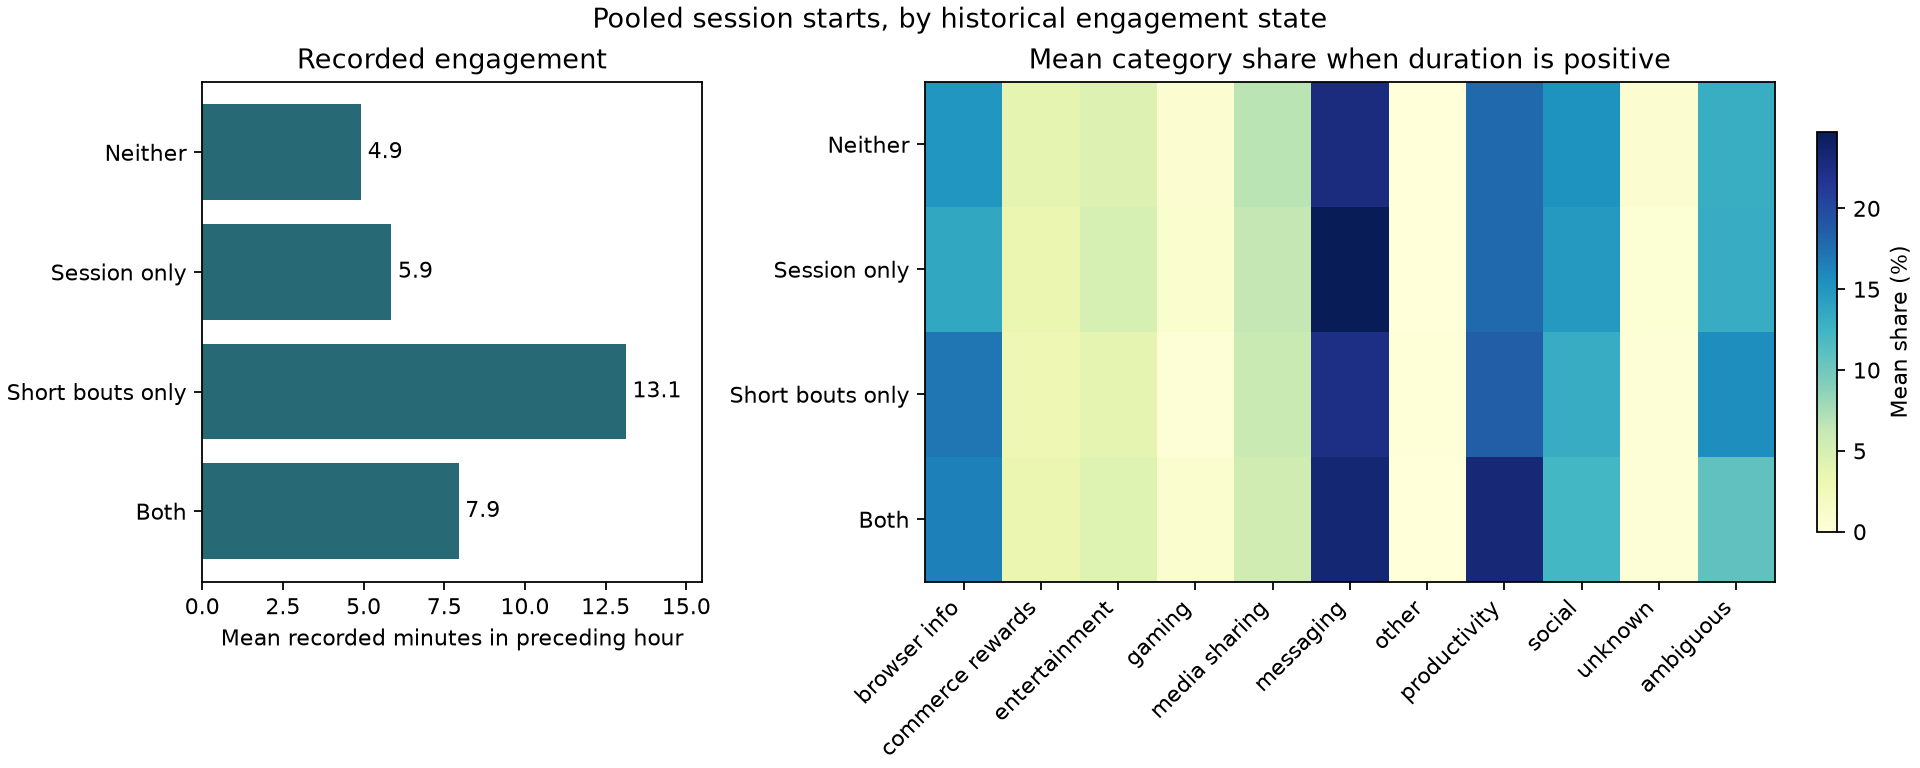

In [35]:
from matplotlib.figure import Figure

fig = Figure(figsize=(12, 4.8), layout="constrained")
ax, heat = fig.subplots(1, 2, gridspec_kw={"width_ratios":[1,1.7]})
short_labels = ["Neither","Session only","Short bouts only","Both"]
minutes = analysis.groupby(label).h60_union_engagement_seconds.mean().reindex(states) / 60
bars = ax.barh(short_labels, minutes, color="#276A76")
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_xlim(0, minutes.max()*1.18)
ax.set_xlabel("Mean recorded minutes in preceding hour")
ax.set_title("Recorded engagement")
mix = analysis.groupby(label)[[f"h60_category_{c}_duration_share" for c in duration_cats]].mean().reindex(states)
image = heat.imshow(mix*100, aspect="auto", cmap="YlGnBu", vmin=0)
heat.set_yticks(range(4), short_labels)
heat.set_xticks(range(len(duration_cats)), [c.replace("_"," ") for c in duration_cats], rotation=45, ha="right")
heat.set_title("Mean category share when duration is positive")
fig.colorbar(image, ax=heat, label="Mean share (%)", shrink=.8)
fig.suptitle("Pooled session starts, by historical engagement state")
figure_path = output_dir / "state_profiles.png"
fig.savefig(figure_path, dpi=160)
display(Image(filename=str(figure_path)))

The short-bout-only group averaged 13.12 recorded minutes in the preceding hour, compared with 4.92 for neither elevated. Among the 219 people observed in both groups, the mean paired difference was 6.37 minutes. The two comparisons weight participants differently, and the repeated lookback windows can overlap.

## 18. Verify time boundaries and replay earlier decisions

Three checks address different failure modes. Hand-computed intervals test union and allocation. A synthetic event stream is reconstructed twice after changing the future, then its earlier decision vector is compared field by field. Finally, a deterministic selection of real decisions is checked independently on a one-second grid and against quantiles calculated directly from preceding rows.

The export is scoped to the observed LSApp session structure. If a new input interleaves sessions for one user or introduces finer timestamp precision, the checks stop the analysis so reconstruction can be reconsidered.

In [36]:
def replay_fixture(records):
    """Small raw-record replay, including an independent pairwise reconstruction-conflict audit."""
    _, b = reconstruct_bouts(records)
    overlap, inside = [], []
    for row in b.itertuples():
        source = records.loc[records.user_id.eq(row.user_id) & records.session_id.eq(row.session_id)]
        other = b.loc[b.user_id.eq(row.user_id) & b.session_id.eq(row.session_id) & b.app_name.ne(row.app_name)]
        overlap.append(row.duration_seconds > 0 and (
            other.duration_seconds.gt(0) & other.start_time.lt(row.end_time) & other.end_time.gt(row.start_time)).any())
        inside.append((source.event_class.eq("interaction") & source.app_name.ne(row.app_name)
                      & source.timestamp.between(row.start_time,row.end_time,inclusive="neither")).any())
    b["cross_app_overlap"], b["other_app_interaction_inside"] = overlap, inside
    b["any_detected_conflict"] = b.cross_app_overlap | b.other_app_interaction_inside
    b = navigation_flags(b).join(mapping, on="app_name")
    edges = records.assign(finish=records.end_time.fillna(records.timestamp)).groupby(session_keys,as_index=False).agg(
        session_start=("timestamp","min"), session_end=("finish","max")).sort_values(order_columns).reset_index(drop=True)
    previous = edges.groupby("user_id").session_end.shift()
    edges["inter_session_gap_seconds"] = (edges.session_start-previous).dt.total_seconds()
    assert edges.inter_session_gap_seconds.dropna().gt(0).all()
    edges["history_session_count"] = edges.groupby("user_id").cumcount()
    result = edges.drop(columns="session_end").join(coverage_at_starts(records,edges))
    result["hour_of_day"], result["day_of_week"] = edges.session_start.dt.hour, edges.session_start.dt.dayofweek
    result["first_observed_session"] = previous.isna()
    for w in (30,60):
        starts = starts_before(edges,w)
        shorts = completions_before(b,edges,w,15,False)
        result[f"prior_sessions_{w}min"], result[f"prior_short_bouts_{w}min"] = starts, shorts
        result = result.join(describe_profiles(historical_raw(b,edges,w)).add_prefix(f"h{w}_"))
    for q in [.75,.90]:
        state, (s_limit,b_limit) = historical_state(edges,starts,shorts,q,30)
        for prefix, values, limit in [("sessions", starts, s_limit), ("short_bouts", shorts, b_limit)]:
            result[f"{prefix}_p{int(100*q)}"] = limit
            result[f"{prefix}_above_p{int(100*q)}"] = values.gt(limit).astype("boolean").where(limit.notna())
        result[f"state_p{int(100*q)}"] = state
    return result, b

from datetime import timedelta

t0 = pd.Timestamp("2018-07-01 12:00")
def mock_event(session, app, start_offset, length, number):
    start = t0 + timedelta(seconds=start_offset)
    end = start + timedelta(seconds=length) if length is not None else pd.NaT
    return (1,session,app,start,"episode" if length is not None else "interaction",
            start if length is not None else pd.NaT,end,length,number)

fixture_columns = session_keys + ["app_name","timestamp","event_class","start_time","end_time","duration_seconds","session_event_number"]
past_rows = [mock_event(j,"Instagram" if j%2 else "Messages",(j-36)*430,5+j%18,1) for j in range(36)]
past_rows += [mock_event(36,"Messages",0,None,1)]
prefix = pd.DataFrame(past_rows,columns=fixture_columns)
future_a = [mock_event(36,"Google Chrome",35,80,2), mock_event(37,"Instagram",960,4,1)]
future_b = [mock_event(36,"Snapchat",25,400,2), mock_event(37,"Google",1100,250,1),
            mock_event(38,"Messages",86450,None,1)]
before, _ = replay_fixture(prefix)
for future in (future_a,future_b):
    revised, _ = replay_fixture(pd.DataFrame(past_rows+future,columns=fixture_columns))
    pd.testing.assert_frame_equal(before, revised.iloc[:len(before)].reset_index(drop=True), check_dtype=False)
assert before.iloc[-1].state_p75 != "insufficient_history"

# A completion on the left edge contributes a visit with zero clipped seconds.
# Completions exactly at the decision and after it contribute neither exposure nor visits.
edge_rows = [mock_event(i,"Messages",s,d,1) for i,(s,d) in enumerate([(-1810,10),(-1805,9),(-10,10),(-5,12)])]
_, edge_bouts = reconstruct_bouts(pd.DataFrame(edge_rows,columns=fixture_columns))
edge_bouts = edge_bouts.assign(cross_app_overlap=False,other_app_interaction_inside=False,any_detected_conflict=False)
edge_bouts = navigation_flags(edge_bouts).join(mapping,on="app_name")
one = pd.DataFrame({"user_id":[1],"session_start":[t0]})
boundary = describe_profiles(historical_raw(edge_bouts,one,30)).iloc[0]
assert boundary.eligible_bout_count == 2 and boundary.union_engagement_seconds == 4

# A–B–A confirms a return. A tied start, a flagged pair and a zero-duration interruption cannot confirm a switch.
rows = [mock_event(0,app,s,d,i) for i,(app,s,d) in enumerate([
    ("Messages",0,2),("Instagram",4,2),("Messages",8,2),("Google",15,3),("Snapchat",15,4),
    ("Messages",25,0),("Instagram",30,2)],start=1)]
_, chain = replay_fixture(pd.DataFrame(rows,columns=fixture_columns))
assert chain.transition.sum() == 2 and chain.revisit.sum() == 1 and chain.start_tied.sum() == 2
print("Synthetic prefix, modified/added future events, window edges, ties, overlaps, zero duration and A–B–A all passed.")

Synthetic prefix, modified/added future events, window edges, ties, overlaps, zero duration and A–B–A all passed.


In [37]:
# Spread checks across chronological rows, including a first session, a warm-up boundary and the last user.
check_rows = np.unique(np.r_[0, 10, 30, np.linspace(0,len(decision_points)-1,24,dtype=int)])
bout_indices = coded_bouts.groupby("user_id").indices
user_starts = decision_features.groupby("user_id").indices
for idx in check_rows:
    row = decision_features.iloc[idx]
    t = int(row.session_start.to_datetime64().astype("datetime64[s]").astype("int64"))
    user_bouts = bout_values[bout_indices.get(row.user_id, np.array([],dtype=int))]
    for w in (30,60):
        lo = t - 60*w
        measured = user_bouts[(user_bouts.end >= lo) & (user_bouts.end < t)]
        occupied = np.zeros((len(duration_cats),w*60), dtype=bool)
        for bout in measured:
            if bout.end > max(bout.start,lo):
                bucket = ambiguous_id if bout.flag else bout.cat
                occupied[bucket,max(bout.start,lo)-lo:bout.end-lo] = True
        any_covered = occupied.any(axis=0)
        allocation = occupied.copy()
        competition = occupied.sum(axis=0) > 1
        allocation[:,competition] = False
        allocation[ambiguous_id,competition] = True
        np.testing.assert_array_equal(allocation.sum(axis=1), history_raw[w].iloc[idx][seconds_cols].to_numpy())
        assert any_covered.sum() == history_profile[w].iloc[idx].union_engagement_seconds
    previous = decision_features.iloc[user_starts[row.user_id]]
    previous = previous.loc[previous.session_start.lt(row.session_start)]
    assert len(previous) == row.history_session_count
    if len(previous) >= 10:
        for stem, source in [("sessions","prior_sessions_60min"), ("short_bouts","prior_short_bouts_60min")]:
            for q in (.75,.90):
                assert np.isclose(previous[source].quantile(q), row[f"baseline_{stem}_p{int(100*q)}"])
assert np.array_equal(completed_sessions[session_keys].to_numpy(), decision_points[session_keys].to_numpy())
assert not set(["session_end","session_span_seconds","recorded_episode_seconds","bout_app_transition_count",
                "bout_app_revisit_count","short_episode_count","union_engagement_seconds"]).intersection(decision_points)
assert decision_points.engagement_pattern_p75.value_counts().to_dict() == reference_labels
print(f"Passed independent per-second allocation for {len(check_rows)} real decisions in each window and prior-only quantile checks.")

Passed independent per-second allocation for 26 real decisions in each window and prior-only quantile checks.


The prefix replay holds the decision row fixed while extending its current session and changing later sessions. Agreement checks temporal isolation on those cases. The sampled real-data occupancy calculation separately checks the interval arithmetic against a second-by-second representation. Neither establishes continuous observation between log entries.

## 19. Export the completed-session and decision-point datasets

Both tables have one row per `(user_id, session_id)`. The completed-session table describes the whole observed session. For Objective 3, read the decision-point table keyed by `decision_timestamp`. Its history fields describe evidence accumulated before that start. An insufficient-history label and all coverage/quality fields travel with the row.

The data dictionary records each column's definition, dtype, unit, missing-value rule and actual missing count. CSV uses UTF-8, an empty field for missing values and the recorded timezone-naive timestamps. Parquet preserves nullable types when PyArrow is installed. Auxiliary tables hold validation evidence and pooled or participant-level summaries.

In [38]:
# Every exported field must have an explicit definition. Unrecognized fields fail the export.
definitions = {}
def define(names, unit, meaning, missing="Always defined on the validated input."):
    for name in names.split():
        definitions[name] = (unit, meaning, missing)

define("user_id", "identifier", "Pseudonymous LSApp participant identifier.")
define("session_id", "identifier", "Supplied session ID, keyed jointly with user_id.")
define("session_start decision_timestamp", "timestamp", "Earliest observed start or point in the current session, on the recorded clock.")
define("session_end", "timestamp", "Latest episode end or point in the completed session.")
define("first_event_time", "timestamp", "Minimum event timestamp in the session.")
define("last_event_time", "timestamp", "Maximum event timestamp in the session.")
define("previous_session_end", "timestamp", "End of the same user's immediately preceding session.", "Missing for the first observed session per user.")
define("inter_session_gap_seconds", "s", "Current start minus previous session end.", "Missing for the first observed session per user.")
define("event_count", "records", "All episode and interaction rows.")
define("episode_count", "records", "Reconstructed episode fragments, including zero duration.")
define("interaction_count", "records", "Point interaction rows.")
define("zero_duration_episode_count", "records", "Episodes with equal endpoints and zero recorded seconds.")
define("short_episode_count", "records", "Episode fragments strictly between zero and 15 seconds.")
define("event_span_seconds", "s", "Latest minus earliest event timestamp.")
define("recorded_episode_seconds", "s", "Sum of episode durations, including overlapping seconds.", "Missing for interaction-only sessions. Measured zero is retained.")
define("session_span_seconds", "s", "Session end minus session start, including gaps.")
define("unique_apps_observed", "apps", "Number of distinct app names across all event classes.")
define("unique_episode_apps", "apps", "Distinct app names appearing on episode rows.")
define("unique_interaction_apps", "apps", "Distinct app names appearing on point interaction rows.")
define("observed_app_transition_count", "changes", "App-name changes in recorded session-event-number order.")
define("observed_app_revisit_count", "returns", "Recorded event transitions returning to an app seen earlier in the same session.")
define("bout_count source_bout_count", "bouts", "All reconstructed bouts, including zero-duration bouts.")
define("short_bout_count", "bouts", "All positive bouts shorter than 15 s, including flagged bouts.")
define("conflicted_bout_count", "bouts", "Bouts with an overlapping other-app positive bout or an interior other-app interaction.")
define("short_bout_unflagged_count short_eligible_count", "bouts", "Positive unflagged bouts shorter than 15 s.")
define("short_bout_conflicted_count", "bouts", "Positive bouts shorter than 15 s with a reconstruction conflict.")
define("positive_bout_count", "bouts", "Bouts with end strictly after start, including flagged bouts.")
define("eligible_bout_count", "bouts", "Positive unflagged bouts used as the category visit denominator.")
define("mapping_uncertain_eligible_count", "bouts", "Eligible visits to apps marked uncertain in the curated lookup.")
define("cross_app_overlap_bout_count", "bouts", "Bouts overlapping a positive bout of a different app within their source session.")
define("other_app_interaction_bout_count", "bouts", "Bouts with an other-app interaction strictly between their endpoints.")
define("tied_start_bout_count", "bouts", "Bouts whose start timestamp is shared by another bout in their source session.")
define("bout_app_transition_count", "changes", "Reliable positive adjacent bouts with different apps; attribute at destination completion.")
define("bout_app_revisit_count", "returns", "Reliable transitions to an app previously observed in a reliable bout in that session.")
define("ambiguous_transition_count", "boundaries", "Adjacent different-app pairs failing the timing, duration or conflict criteria.")
define("snapchat_eligible_count", "bouts", "Eligible Snapchat visits transferable from media sharing to messaging.")
define("snapchat_attributed_seconds", "s", "Union seconds credited to clean Snapchat intervals under the primary mapping.")
define("union_engagement_seconds", "s", "Length of the union of positive completed app intervals; omit gaps.")
define("short_bout_ratio", "fraction", "Positive unflagged bouts under 15 s divided by all positive unflagged bouts.", "Missing if no eligible visits.")
define("mapping_uncertain_bout_share", "fraction", "Eligible visits with uncertain app mapping divided by eligible visits.", "Missing if no eligible visits.")
define("bout_switching_rate", "changes/min", "Reliable bout transitions divided by union engagement minutes.", "Missing for zero or missing union seconds.")
define("dominant_category", "category", "Unique largest category by attributed union duration.", "Missing for no duration, tied maximum, or an ambiguous/unknown winner.")
define("prior_observed_dates", "dates", "Distinct recorded event dates with at least one timestamp strictly before the decision, including today if already observed.")
define("seconds_since_first_observation", "s", "Decision time minus the user's earliest recorded event timestamp.")
define("prior_event_count", "records", "Prepared event timestamps in the lookback window, excluding the decision instant.")
define("window_reaches_before_first_record", "boolean", "True when the lower window edge predates the user's first record; false does not certify continuous recording.")
define("insufficient_state_history", "boolean", "Fewer than 30 preceding session starts.")
define("history_session_count", "starts", "Number of earlier session starts contributing frequency observations to the expanding reference.")
define("first_observed_session", "boolean", "First available session start for the participant.")
define("hour_of_day", "hour", "Hour of the recorded decision timestamp, 0 to 23.")
define("day_of_week", "weekday", "Recorded weekday of decision, Monday 0 to Sunday 6.")
define("engagement_pattern_p75", "category", "Historical engagement state observed at the current session start: four strict personal P75 patterns or insufficient_history.")
for w in (30,60):
    define(f"sessions_last_{w}min","starts",f"Session starts in the closed {w}-minute window including the current start.")
    define(f"prior_sessions_{w}min","starts",f"Prior starts in [decision minus {w} minutes, decision).")
    define(f"prior_short_bouts_{w}min","bouts",f"Unflagged completed bouts with 0 < duration < 15 s ending in the preceding {w}-minute window.")
for p in (75,90):
    for stem, noun, flag in [("sessions","prior session starts","elevated_session_frequency"),
                              ("short_bouts","prior short unflagged bouts","elevated_short_bout_frequency")]:
        define(f"baseline_{stem}_p{p}","count",f"Personal expanding P{p} of earlier 60-minute counts of {noun}.",
               "Missing before ten preceding starts.")
        define(flag if p==75 else flag+"_p90","boolean",f"Current 60-minute count of {noun} strictly exceeds the personal P{p}.",
               "Missing before ten preceding starts.")
for c in categories:
    define(f"category_{c}_bout_count","bouts",f"Positive unflagged visits assigned to {c} under the primary mapping.")
    define(f"category_{c}_bout_share","fraction",f"Eligible {c} visits divided by all eligible visits.", "Missing if no eligible visits.")
for c in duration_cats:
    define(f"category_{c}_seconds","s",f"Union seconds attributed once to {c}; conflicted attribution is assigned to ambiguous.")
    define(f"category_{c}_duration_share","fraction",f"Attributed {c} seconds divided by total union seconds, including unknown and ambiguous.",
           "Missing for a zero or missing union.")

def schema_for(table, name):
    rows = []
    for column, values in table.items():
        scope = ""
        key = column
        if column.startswith(("h30_","h60_")):
            window, key = column.split("_", 1)
            scope = f" At decision start with a {window[1:]}-minute lookback."
        unit, meaning, null_rule = definitions[key]
        if key in seconds_cols + ["snapchat_attributed_seconds","union_engagement_seconds"]:
            null_rule = ("Missing when the completed session has no episodes; zero if all durations are zero."
                         if name == "completed_sessions" else "Zero if there are no contributing completed intervals; refer to coverage flags.")
        rows.append((name,column,str(values.dtype),unit,meaning+scope,null_rule,int(values.isna().sum()),100*values.isna().mean()))
    return pd.DataFrame(rows, columns=["dataset","column","dtype","unit","definition","missing_rule","missing_rows","missing_pct"])

schema = pd.concat([schema_for(completed_sessions,"completed_sessions"), schema_for(decision_points,"decision_points")],ignore_index=True)
assert not schema.duplicated(["dataset","column"]).any()
display(schema.groupby("dataset").agg(columns=("column","size"),columns_with_missing=("missing_rows",lambda x:x.gt(0).sum())))

,columns,columns_with_missing
dataset,,
completed_sessions,90,41
decision_points,148,59


In [39]:
import tempfile
from pathlib import Path
import platform

tables = {"completed_sessions":completed_sessions, "decision_points":decision_points}
auxiliary = {
    "schema":schema, "state_sensitivity":sensitivity.reset_index(), "state_sensitivity_by_user":sensitivity_by_user,
    "mapping_sensitivity":mapping_sensitivity, "weekly_stability":weekly,
    "state_profiles_pooled":pooled_long, "state_profiles_paired":paired,
}
use_parquet = find_spec("pyarrow") is not None
def read_csv_as_schema(path, table):
    date_cols = [c for c in table if pd.api.types.is_datetime64_any_dtype(table[c])]
    types = {c:str(table[c].dtype) for c in table if c not in date_cols}
    return pd.read_csv(path, dtype=types, parse_dates=date_cols, keep_default_na=False, na_values=[""],
                       float_precision="round_trip")

# Write and read back the two full tables before promoting the checked files.
with tempfile.TemporaryDirectory(dir=output_dir) as tmp:
    stage = Path(tmp)
    for name, table in tables.items():
        csv_path = stage / f"{name}.csv"
        table.to_csv(csv_path,index=False,encoding="utf-8",date_format="%Y-%m-%d %H:%M:%S")
        restored = read_csv_as_schema(csv_path,table)
        pd.testing.assert_frame_equal(restored, table.reset_index(drop=True), check_exact=False, rtol=1e-12, atol=1e-12)
        del restored
        if use_parquet:
            path = stage / f"{name}.parquet"
            table.to_parquet(path,engine="pyarrow",compression="snappy",index=False)
            pd.testing.assert_frame_equal(pd.read_parquet(path),table.reset_index(drop=True),check_exact=True)
    for name, table in auxiliary.items():
        table.to_csv(stage / f"{name}.csv",index=False)
    for path in stage.iterdir():
        path.replace(output_dir / path.name)

print("Validated CSV" + (" and Parquet" if use_parquet else "") + " exports")
for name, table in tables.items():
    print(f"{name}: {len(table):,} rows × {table.shape[1]} columns")
display(schema[schema.missing_rows.gt(0)].sort_values("missing_pct",ascending=False).groupby("dataset").head(4))

Validated CSV exports
completed_sessions: 70,979 rows × 90 columns
decision_points: 70,979 rows × 148 columns


,dataset,column,dtype,unit,definition,missing_rule,missing_rows,missing_pct
170,decision_points,h30_dominant_category,string,category,Unique largest category by attributed union du...,"Missing for no duration, tied maximum, or an a...",30654,43.187422
146,decision_points,h30_category_browser_info_bout_share,float64,fraction,Eligible browser_info visits divided by all el...,Missing if no eligible visits.,25411,35.800730
147,decision_points,h30_category_commerce_rewards_bout_share,float64,fraction,Eligible commerce_rewards visits divided by al...,Missing if no eligible visits.,25411,35.800730
153,decision_points,h30_category_productivity_bout_share,float64,fraction,Eligible productivity visits divided by all el...,Missing if no eligible visits.,25411,35.800730
89,completed_sessions,dominant_category,string,category,Unique largest category by attributed union du...,"Missing for no duration, tied maximum, or an a...",21476,30.256837
72,completed_sessions,category_productivity_bout_share,float64,fraction,Eligible productivity visits divided by all el...,Missing if no eligible visits.,16361,23.050480
74,completed_sessions,category_unknown_bout_share,float64,fraction,Eligible unknown visits divided by all eligibl...,Missing if no eligible visits.,16361,23.050480
73,completed_sessions,category_social_bout_share,float64,fraction,Eligible social visits divided by all eligible...,Missing if no eligible visits.,16361,23.050480


The completed-session file retains 70,979 rows across 90 fields. The decision-point file contains the same keys across 148 fields. The data dictionary gives the denominator for each ratio and identifies exactly where missing values occur.

## 20. Implementation summary and Objective 3 handoff

Read the implementation summary alongside the field-level dictionary and validation tables. A future simulator can take the decision-point row as observable history, including the coverage flags and missing values. The completed-session table is available for retrospective characterization. Its end-of-session measurements must stay outside the predictor vector at the same start.

In [40]:
from importlib.metadata import version

def relative_link(file, base):
    import os
    return Path(os.path.relpath(file,base)).as_posix()

report_path = project_root / "Documents" / "Drafts" / "Objective_2_Implementation_Summary.md"
def link(file, title):
    return f"[{title}](<{relative_link(file,report_path.parent)}>)"

def markdown_table(headers, rows):
    return "\n".join(["| " + " | ".join(headers) + " |", "|" + "|".join("---" for _ in headers) + "|"]
                     + ["| " + " | ".join(map(str,row)) + " |" for row in rows])

ref_rows = [(name, f"{int(row.observed):,}") for name,row in reference.iterrows()]
state_rows = [(name, f"{count:,}") for name,count in reference_labels.items()]
sens_rows = [(name, f"{r.changed_pct:.2f}%", f"{r.common_changed_pct:.2f}%", f"{r.mean_person_pct:.2f}%")
             for name,r in sensitivity.iloc[1:].iterrows()]
dataset_rows = []
for name,table in tables.items():
    paths = [link(output_dir / f"{name}.csv","CSV")]
    if use_parquet:
        paths.insert(0,link(output_dir / f"{name}.parquet","Parquet"))
    dataset_rows.append((name," · ".join(paths),f"{len(table):,}",table.shape[1], int(table.isna().any().sum())))
means = analysis.groupby(label).h60_union_engagement_seconds.mean()/60
paired_duration = paired.loc[paired.descriptor.eq("h60_union_engagement_seconds")].set_index("state")
snap60 = mapping_sensitivity.set_index("scope").loc["60 minutes"]
total_na = int(completed_sessions.union_engagement_seconds.isna().sum())
zero_duration = int(completed_sessions.union_engagement_seconds.eq(0).sum())
removed = completed_sessions.recorded_episode_seconds.sum()-completed_sessions.union_engagement_seconds.sum()
source_digest = hashlib.sha256(data_path.read_bytes()).hexdigest()
map_digest = hashlib.sha256(mapping_path.read_bytes()).hexdigest()
report = f"""# Objective 2 implementation summary

The historical engagement state is observed at the current session's start. The enriched analysis reproduced all supplied reference counts and both output tables passed full-file round-trip checks.

## A. Existing implementation

Sections 1–9 retain Objective 1's episode and interaction stream, the original session keys, observed event counts and navigation, three original time measures, conservative same-app merging, conflict detection, both window frequencies and expanding personal P75/P90 baselines. Assignment uses a strict comparison and requires 30 earlier starts. Percentiles become available after ten.

## B. New measurements

| Measurement | Inputs and definition |
|---|---|
| Recorded engagement | Union of positive reconstructed start–end intervals. Window histories use strictly earlier completions and clip the left edge. |
| App composition | Exact app name mapped to one primary group, an alternate and an uncertainty note. Visits count positive unflagged bouts. Duration covers all positive intervals with an explicit ambiguous bucket. Shares retain unknowns in their denominators. |
| Bout navigation | App identity, start/end times, ties, earlier apps and conflict flags determine supported adjacent transitions and revisits. Short concentration is the fraction of eligible visits under 15 seconds. Switching rate divides supported transitions by union minutes. |
| Historical coverage | Earlier record timestamps, distinct observed dates, preceding starts, elapsed time, available window span, contributing bouts and insufficient-history flags. |
| Characterization | Matched-window sensitivities, app-mapping substitution, disjoint observed weeks, pooled state distributions and within-participant comparisons. |

The {len(mapping)}-name {link(mapping_path,"versioned mapping")} covers the entire input. Three app identities have an unresolved primary category. The lookup explains every assignment. Named Snapchat visit counts and attributed seconds permit the alternative mapping for each row.

## C. Reference results

{markdown_table(["Reference measure","Reproduced"],ref_rows)}

{markdown_table(["P75 state","Starts"],state_rows)}

Every label count matches. No threshold or reference definition changed.

## D. Final datasets and missingness

{markdown_table(["Dataset","Files","Rows","Columns","Columns with missing values"],dataset_rows)}

The {link(output_dir/"schema.csv","data dictionary")} lists every column, dtype, unit, meaning, missingness rule and missing count. CSV blanks represent missing values. Both tables use one row per user–session pair. All current-session outcomes are confined to the completed table.

- Completed sessions have {total_na:,} missing union durations from interaction-only sessions and {zero_duration:,} measured zero durations.
- The decision table has {decision_points.inter_session_gap_seconds.isna().sum():,} missing gaps and {decision_points.baseline_sessions_p75.isna().sum():,} missing P75 session baselines. {decision_points.h60_union_engagement_seconds.eq(0).sum():,} starts have zero recorded union duration in the preceding hour, so their duration shares are undefined. The 60-minute dominant category is unresolved at {decision_points.h60_dominant_category.isna().sum():,} starts.
- Raw telemetry and the prepared workbook remain the project inputs. Input workbook SHA-256 is `{source_digest}`. Lookup SHA-256 is `{map_digest}`.

## E. Validation and findings

The interval union removes {int(removed):,} duplicate seconds from episode sums. Conservative attribution places {int(completed_sessions.category_ambiguous_seconds.sum()):,} covered seconds in the ambiguous category. The event sequence contains {int(sessions.observed_app_transition_count.sum()):,} name transitions; the bout sequence supports {int(completed_sessions.bout_app_transition_count.sum()):,} transitions and {int(completed_sessions.bout_app_revisit_count.sum()):,} revisits.

All category counts and shares reconcile, all historical unions respect their window length, and each short-bout total matches the original. The notebook tests clipped and tied intervals, changes and additions to synthetic future events, and one-second occupancy at {len(check_rows)} real decisions in both windows. Source sessions were strictly separated for every user. Full CSV read-back restored both schemas and values{", and the Parquet files passed exact equality checks" if use_parquet else ""}.

{markdown_table(["Alternative","All starts changed","Jointly eligible changed","Mean user change, all starts"],sens_rows)}

The {link(output_dir/"state_sensitivity.csv","sensitivity summary")} and {link(output_dir/"state_sensitivity_by_user.csv","per-user results")} give all denominators. Warm-up changes alter eligibility. Among starts eligible under both rules, warm-up changes leave state assignments intact. Moving Snapchat to messaging changes the 60-minute dominant category at {int(snap60.changed_dominant):,} starts ({snap60.changed_dominant_pct:.2f}%). The primary state is independent of app coding. See the {link(output_dir/"mapping_sensitivity.csv","mapping comparison")}.

Mean recorded minutes in the preceding hour are {means["neither_elevated"]:.2f} for neither elevated, {means["session_only"]:.2f} for session only, {means["short_bout_only"]:.2f} for short bouts only and {means["both_elevated"]:.2f} for both. For the {int(paired_duration.loc["short_bout_only","people"])} people observed in both short-bout-only and neither-elevated states, the mean within-person difference is {paired_duration.loc["short_bout_only","mean_paired_difference"]/60:.2f} minutes. The {link(output_dir/"state_profiles.png","figure")}, {link(output_dir/"state_profiles_pooled.csv","pooled distributions")} and {link(output_dir/"state_profiles_paired.csv","paired contrasts")} include category mix, fragmentation, revisit and clock descriptors.

Only {len(weekly)} users supply two adjacent fully observed-date weeks. The median absolute difference is {weekly.absolute_daily_start_change.median():.2f} starts per observed day; median category total-variation distance is {weekly.category_tv_distance.median():.3f}. The {link(output_dir/"weekly_stability.csv","weekly pairs")} describe this selected subset.

## F. Limitations

Recorded intervals measure app engagement. LSApp lacks screen state, notification delivery, motives, within-app activity, questionnaire scores and clinical outcomes. Clock time is used as recorded. A date with a record establishes partial observation; silent days and data gaps have unknown coverage. Conservative ambiguity handling can understate attributed category exposure and supported navigation. Dominance abstains for ties, unresolved winners and empty windows. Ratios have different availability by state. The thresholds, windows and warm-up are operational choices. Between-state differences remain descriptive.

## G. Objective 3 handoff

Use `decision_points` and its `decision_timestamp` to initialize observable history. Retain the two defining counts, P75/P90 references, state, recorded minutes, category proportions, transition/revisit measures, calendar context and all coverage/quality indicators. Preserve warm-up and unavailable ratios as explicit conditions. Completed-session fields can support retrospective calibration. Psychological states, intervention responses and rewards require separate modeling and evidence.

## Reproduction

Run the {link(project_root/"Notebooks/Research_Project_Objective_2_Guided.ipynb","guided notebook")} top-to-bottom from the project root or Notebooks directory. Read the {link(project_root/"Documents/Drafts/objective_2_lsapp_behavioural_indicators.pdf","local methods memo")} for the measurement rationale and source studies. The {link(project_root/"Notebooks/Backups/Research_Project_Objective_2_Guided_pre_extension.ipynb","pre-extension backup")} preserves the prior notebook. This run used Python {platform.python_version()}, pandas {pd.__version__}, NumPy {np.__version__}, openpyxl {version("openpyxl")}, Matplotlib {version("matplotlib")}{", and PyArrow "+version("pyarrow") if use_parquet else ""}. No random sampling is used.
"""
report_path.write_text(report, encoding="utf-8")
print(f"Implementation summary: {report_path.relative_to(project_root)}")
display(distribution)

Implementation summary: Documents\Drafts\Objective_2_Implementation_Summary.md


,Session starts,Share of all starts (%)
engagement_pattern_p75,,
neither_elevated,42372,59.70
short_bout_only,10324,14.55
insufficient_history,7925,11.17
session_only,6849,9.65
both_elevated,3509,4.94
